In [1]:
import pandas as pd
import ast
import matplotlib.pyplot as plt
from pathlib import Path

INPUT_FILE = Path(
    r"C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\final_labour_market_normalized.csv"
)

df = pd.read_csv(INPUT_FILE)

print("=" * 70)
print("LABOUR MARKET ANALYSIS DATASET")
print("=" * 70)

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nColumns:")
print(df.columns.tolist())

LABOUR MARKET ANALYSIS DATASET
Rows: 19207
Columns: 35

Columns:
['job_id', 'source_id', 'title', 'company', 'location', 'description', 'salary_min', 'salary_max', 'salary_avg', 'created', 'contract_type', 'contract_time', 'url', 'source', 'title_clean', 'description_clean', 'industry', 'industry_original', 'second_pass_industry', 'industry_before_second_pass', 'technical_skills', 'soft_skills', 'tools_and_technologies', 'certifications', 'licenses', 'education_required', 'experience_required', 'languages', 'status', 'technical_skills_normalized', 'soft_skills_normalized', 'tools_and_technologies_normalized', 'certifications_normalized', 'licenses_normalized', 'languages_normalized']


In [2]:
print("=" * 70)
print("BASIC DATASET PROFILE")
print("=" * 70)

print("Rows:", len(df))
print("Columns:", len(df.columns))

print("\nMissing values:")
print(df.isna().sum().sort_values(ascending=False))

print("\nDuplicate job IDs:")
print(df["job_id"].duplicated().sum())

BASIC DATASET PROFILE
Rows: 19207
Columns: 35

Missing values:
second_pass_industry                 18500
education_required                   17754
experience_required                  10365
salary_max                            2472
salary_min                            2432
salary_avg                            2432
languages                                0
soft_skills                              0
tools_and_technologies                   0
certifications                           0
licenses                                 0
job_id                                   0
status                                   0
technical_skills                         0
soft_skills_normalized                   0
tools_and_technologies_normalized        0
certifications_normalized                0
licenses_normalized                      0
technical_skills_normalized              0
industry_original                        0
industry_before_second_pass              0
source_id                         

In [3]:
industry_counts = (
    df["industry"]
    .value_counts()
    .sort_values(ascending=False)
)

print("=" * 70)
print("INDUSTRY DEMAND")
print("=" * 70)

print(industry_counts)

INDUSTRY DEMAND
industry
Other                            9111
Engineering                      2561
Manufacturing                    1188
Construction                     1174
Finance and Banking              1064
Education                         998
Transport and Logistics           874
IT and Technology                 610
Hospitality and Food Services     316
Automotive                        239
Healthcare                        230
Legal                             227
Human Resources                   204
Retail                            189
Marketing and Advertising         137
Insurance                          48
Real Estate                        37
Name: count, dtype: int64


In [4]:
industry_percent = (
    df["industry"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("\nIndustry percentages:")
print(industry_percent)


Industry percentages:
industry
Other                            47.44
Engineering                      13.33
Manufacturing                     6.19
Construction                      6.11
Finance and Banking               5.54
Education                         5.20
Transport and Logistics           4.55
IT and Technology                 3.18
Hospitality and Food Services     1.65
Automotive                        1.24
Healthcare                        1.20
Legal                             1.18
Human Resources                   1.06
Retail                            0.98
Marketing and Advertising         0.71
Insurance                         0.25
Real Estate                       0.19
Name: proportion, dtype: float64


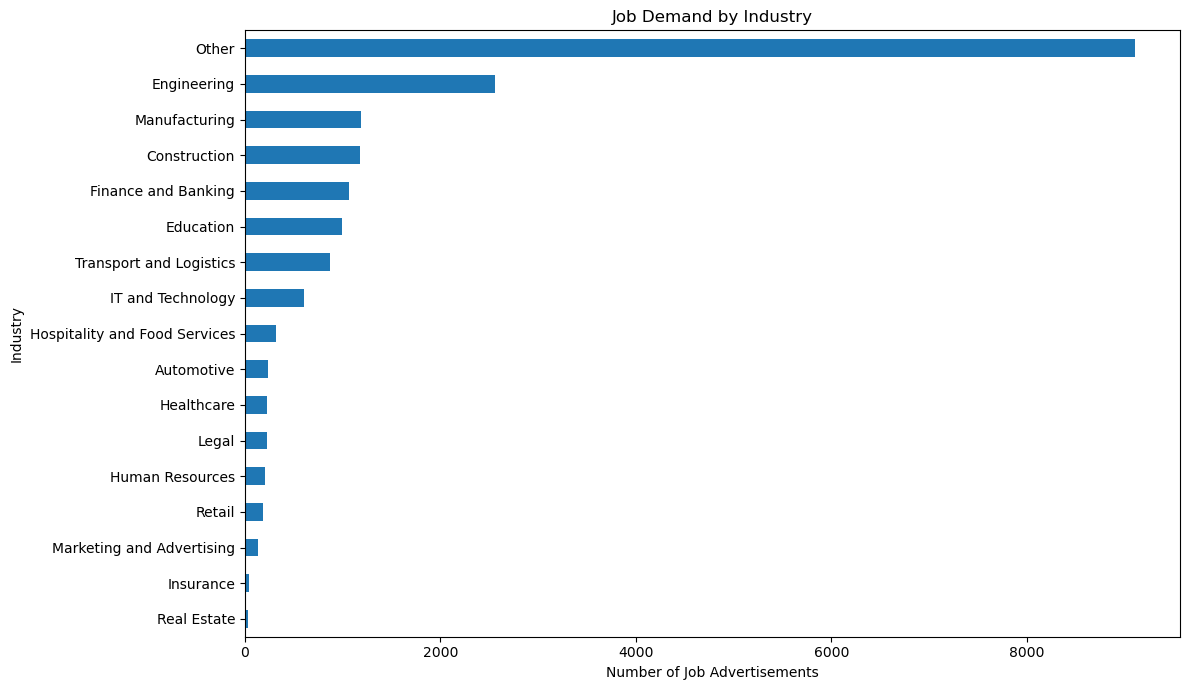

In [5]:
plt.figure(figsize=(12, 7))

industry_counts.sort_values().plot(kind="barh")

plt.title("Job Demand by Industry")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

In [6]:
other_count = (df["industry"] == "Other").sum()
other_percentage = (other_count / len(df)) * 100

print("=" * 70)
print("OTHER INDUSTRY ANALYSIS")
print("=" * 70)

print("Other jobs:", other_count)
print("Percentage:", round(other_percentage, 2), "%")

OTHER INDUSTRY ANALYSIS
Other jobs: 9111
Percentage: 47.44 %


In [7]:
# ============================================================
# TECHNICAL SKILL DEMAND
# ============================================================

def parse_skill_list(value):
    """
    Convert a stored skill list into a Python list.
    Handles actual lists and string representations of lists.
    """
    
    if pd.isna(value):
        return []
    
    if isinstance(value, list):
        return value
    
    if isinstance(value, str):
        try:
            parsed = ast.literal_eval(value)
            
            if isinstance(parsed, list):
                return parsed
            
            return []
        
        except (ValueError, SyntaxError):
            return []
    
    return []


df["technical_skills_parsed"] = df[
    "technical_skills_normalized"
].apply(parse_skill_list)

skill_counts = {}

for skills in df["technical_skills_parsed"]:
    for skill in skills:
        if isinstance(skill, str):
            skill = skill.strip()
            
            if skill:
                skill_counts[skill] = skill_counts.get(skill, 0) + 1


technical_skill_counts = (
    pd.Series(skill_counts)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP TECHNICAL SKILLS")
print("=" * 70)

print(
    technical_skill_counts.head(30)
)

TOP TECHNICAL SKILLS
Electrical Installation    628
Financial Analysis         156
Forklift Operation         120
Electrical Maintenance      81
Mechanical Maintenance      80
Financial Modelling         73
Mechanical Engineering      72
Welding                     66
CNC Milling                 65
CNC Programming             64
Mechanical Design           63
CNC Machining               61
Data Analysis               50
Java                        48
Python                      44
CAD                         44
Fabrication                 43
Maintenance                 40
MIG Welding                 39
Mechanical                  39
AI                          37
CNC Turning                 37
Project Management          36
Electrical Design           33
Carpentry                   33
TIG Welding                 31
AWS                         30
Machine Learning            29
Electrical                  28
Azure                       28
dtype: int64


In [8]:
# ============================================================
# TECHNICAL SKILL COVERAGE
# ============================================================

technical_jobs = (
    df["technical_skills_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("TECHNICAL SKILL COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one technical skill: "
    f"{technical_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{technical_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 technical skills:")

display(
    technical_skill_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

TECHNICAL SKILL COVERAGE
Jobs containing at least one technical skill: 3,593 / 19,207
Coverage: 18.71%

Top 20 technical skills:


,job_count
Electrical Installation,628
Financial Analysis,156
Forklift Operation,120
Electrical Maintenance,81
Mechanical Maintenance,80
Financial Modelling,73
Mechanical Engineering,72
Welding,66
CNC Milling,65
CNC Programming,64


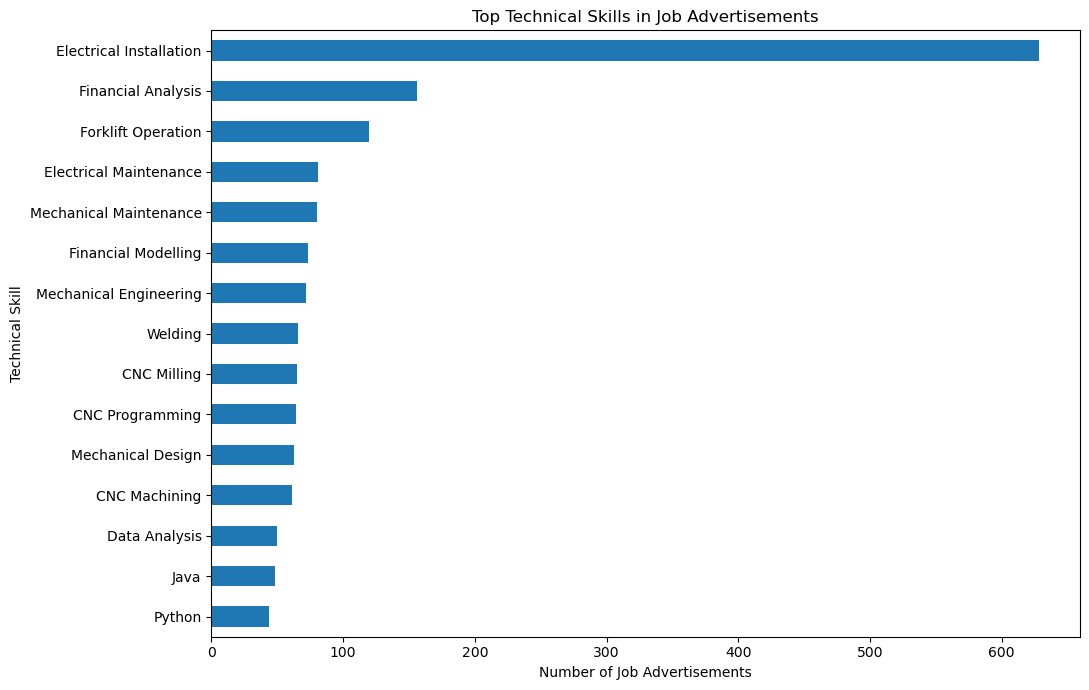

In [9]:
# ============================================================
# TOP TECHNICAL SKILLS VISUALISATION
# ============================================================

top_technical = technical_skill_counts.head(15).sort_values()

plt.figure(figsize=(11, 7))

top_technical.plot(kind="barh")

plt.title("Top Technical Skills in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Technical Skill")

plt.tight_layout()
plt.show()

In [10]:
# ============================================================
# SOFT SKILL DEMAND
# ============================================================

df["soft_skills_parsed"] = df[
    "soft_skills_normalized"
].apply(parse_skill_list)

soft_skill_counts_dict = {}

for skills in df["soft_skills_parsed"]:
    for skill in skills:
        if isinstance(skill, str):
            skill = skill.strip()

            if skill:
                soft_skill_counts_dict[skill] = (
                    soft_skill_counts_dict.get(skill, 0) + 1
                )

soft_skill_counts = (
    pd.Series(soft_skill_counts_dict)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP SOFT SKILLS")
print("=" * 70)

print(soft_skill_counts.head(30))

TOP SOFT SKILLS
Communication                           2352
Problem Solving                         2184
Attention to Detail                     1944
Teamwork                                1843
Leadership                              1449
Customer Service                         824
Time Management                          396
Proactive                                336
Reliable                                 170
Organised                                151
Project Management                       119
Flexibility                              107
Listening                                106
Enthusiasm                               104
Organisation                              95
Passion                                   87
Creativity                                72
Collaboration                             69
Reliability                               67
Dedication                                64
Detail Oriented                           63
Motivated                              

In [11]:
# ============================================================
# SOFT SKILL COVERAGE
# ============================================================

soft_skill_jobs = (
    df["soft_skills_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("SOFT SKILL COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one soft skill: "
    f"{soft_skill_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{soft_skill_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 soft skills:")

display(
    soft_skill_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

SOFT SKILL COVERAGE
Jobs containing at least one soft skill: 6,424 / 19,207
Coverage: 33.45%

Top 20 soft skills:


,job_count
Communication,2352
Problem Solving,2184
Attention to Detail,1944
Teamwork,1843
Leadership,1449
Customer Service,824
Time Management,396
Proactive,336
Reliable,170
Organised,151


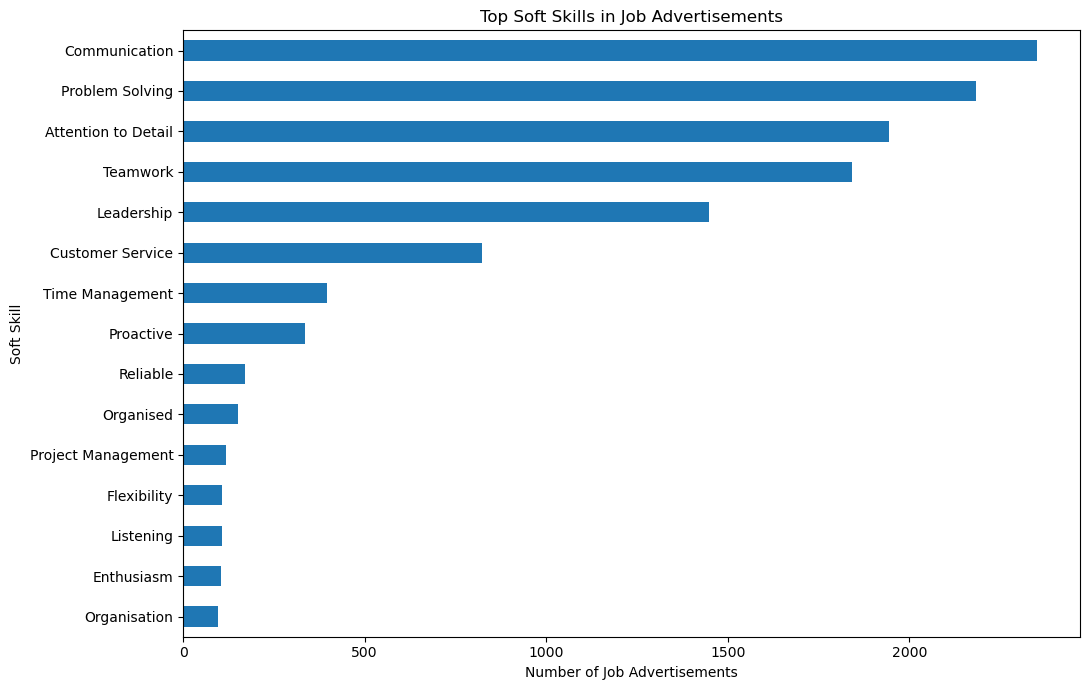

In [12]:
# ============================================================
# TOP SOFT SKILLS VISUALISATION
# ============================================================

top_soft = soft_skill_counts.head(15).sort_values()

plt.figure(figsize=(11, 7))

top_soft.plot(kind="barh")

plt.title("Top Soft Skills in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Soft Skill")

plt.tight_layout()
plt.show()

In [13]:
# ============================================================
# TOOLS & TECHNOLOGIES DEMAND
# ============================================================

df["tools_parsed"] = df[
    "tools_and_technologies_normalized"
].apply(parse_skill_list)

tool_counts_dict = {}

for tools in df["tools_parsed"]:
    for tool in tools:
        if isinstance(tool, str):
            tool = tool.strip()

            if tool:
                tool_counts_dict[tool] = (
                    tool_counts_dict.get(tool, 0) + 1
                )

tool_counts = (
    pd.Series(tool_counts_dict)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP TOOLS & TECHNOLOGIES")
print("=" * 70)

print(tool_counts.head(30))

TOP TOOLS & TECHNOLOGIES
Uber Eats app         84
Microsoft Excel       58
SAP                   29
AWS                   25
AutoCAD               21
Azure                 17
CAD                   16
Uber Eats App         14
Microsoft Fabric      12
Tablet                11
Python                11
Sage                  11
Revit                  9
Forklift               9
Forklift Operation     9
Terraform              9
SQL                    8
Fanuc                  8
AI                     7
Tool Technology        7
Solidworks             6
Autodesk Inventor      5
Databricks             5
Microsoft Dynamics     5
ERP system             5
Power BI               5
Fanuc Control          5
Microsoft              5
Hand tools             5
Haas Fusion            4
dtype: int64


In [14]:
# ============================================================
# TOOLS & TECHNOLOGIES COVERAGE
# ============================================================

tool_jobs = (
    df["tools_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("TOOLS & TECHNOLOGIES COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one tool/technology: "
    f"{tool_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{tool_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 tools and technologies:")

display(
    tool_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

TOOLS & TECHNOLOGIES COVERAGE
Jobs containing at least one tool/technology: 779 / 19,207
Coverage: 4.06%

Top 20 tools and technologies:


,job_count
Uber Eats app,84
Microsoft Excel,58
SAP,29
AWS,25
AutoCAD,21
Azure,17
CAD,16
Uber Eats App,14
Microsoft Fabric,12
Tablet,11


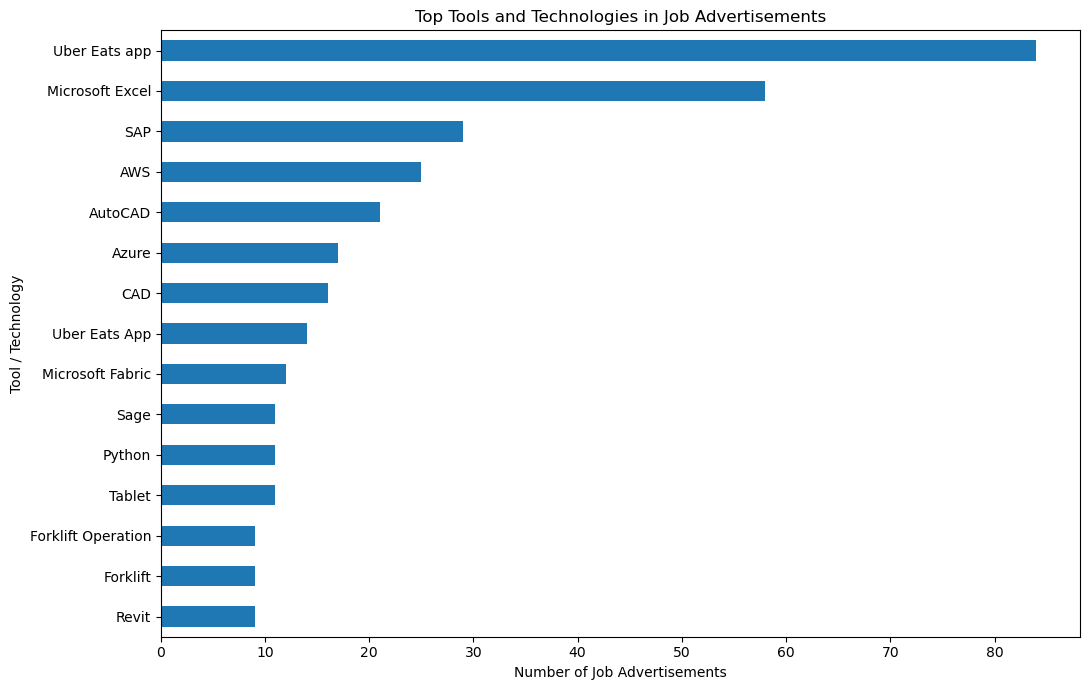

In [15]:
# ============================================================
# TOP TOOLS & TECHNOLOGIES VISUALISATION
# ============================================================

top_tools = tool_counts.head(15).sort_values()

plt.figure(figsize=(11, 7))

top_tools.plot(kind="barh")

plt.title("Top Tools and Technologies in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Tool / Technology")

plt.tight_layout()
plt.show()

In [16]:
# ============================================================
# CERTIFICATION DEMAND
# ============================================================

df["certifications_parsed"] = df[
    "certifications_normalized"
].apply(parse_skill_list)

certification_counts_dict = {}

for certifications in df["certifications_parsed"]:
    for certification in certifications:
        if isinstance(certification, str):
            certification = certification.strip()

            if certification:
                certification_counts_dict[certification] = (
                    certification_counts_dict.get(certification, 0) + 1
                )

certification_counts = (
    pd.Series(certification_counts_dict)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP CERTIFICATIONS")
print("=" * 70)

print(certification_counts.head(30))

TOP CERTIFICATIONS
ACCA                                    68
CIMA                                    39
ACA                                     34
CSCS Card                               16
NVQ                                      9
QTS                                      8
CPCS                                     8
NPORS                                    7
Qualified Accountant                     5
CPC                                      4
NMC Registration                         4
CE Licence                               3
IPAF                                     3
Part Qualified Accountant                3
First Aid Certificate                    3
Enhanced DBS Check                       3
AAT                                      3
Part Qualified Management Accountant     3
SMSTS                                    3
SIA Licence                              3
ACCA study support                       2
Digi Card                                2
CQC Registration                   

In [17]:
# ============================================================
# CERTIFICATION COVERAGE
# ============================================================

certification_jobs = (
    df["certifications_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("CERTIFICATION COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one certification: "
    f"{certification_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{certification_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 certifications:")

display(
    certification_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

CERTIFICATION COVERAGE
Jobs containing at least one certification: 364 / 19,207
Coverage: 1.90%

Top 20 certifications:


,job_count
ACCA,68
CIMA,39
ACA,34
CSCS Card,16
NVQ,9
QTS,8
CPCS,8
NPORS,7
Qualified Accountant,5
CPC,4


In [18]:
# ============================================================
# LICENCE DEMAND
# ============================================================

df["licenses_parsed"] = df[
    "licenses_normalized"
].apply(parse_skill_list)

license_counts_dict = {}

for licenses in df["licenses_parsed"]:
    for license in licenses:
        if isinstance(license, str):
            license = license.strip()

            if license:
                license_counts_dict[license] = (
                    license_counts_dict.get(license, 0) + 1
                )

license_counts = (
    pd.Series(license_counts_dict)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP LICENCES")
print("=" * 70)

print(license_counts.head(30))

TOP LICENCES
Driving Licence                       133
SIA Licence                            67
Full UK Driving Licence                24
HGV Class 1 Licence                    22
HGV Class 2 Licence                    21
CSCS Card                              16
HGV Class 1                            13
FLT Licence                             9
Forklift Operation                      8
HGV Class 2                             7
Full driving licence                    7
Scooter license                         6
Bike license                            6
Car license                             6
Driver Licence                          6
Forklift Licence                        6
HGV Licence                             6
C1                                      5
HGV Driver Licence                      4
SC Clearance                            4
LGV Licence                             4
Full Driving Licence                    3
car license                             3
Valid driving license

In [19]:
# ============================================================
# LICENCE COVERAGE
# ============================================================

license_jobs = (
    df["licenses_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("LICENCE COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one licence: "
    f"{license_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{license_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 licences:")

display(
    license_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

LICENCE COVERAGE
Jobs containing at least one licence: 528 / 19,207
Coverage: 2.75%

Top 20 licences:


,job_count
Driving Licence,133
SIA Licence,67
Full UK Driving Licence,24
HGV Class 1 Licence,22
HGV Class 2 Licence,21
CSCS Card,16
HGV Class 1,13
FLT Licence,9
Forklift Operation,8
HGV Class 2,7


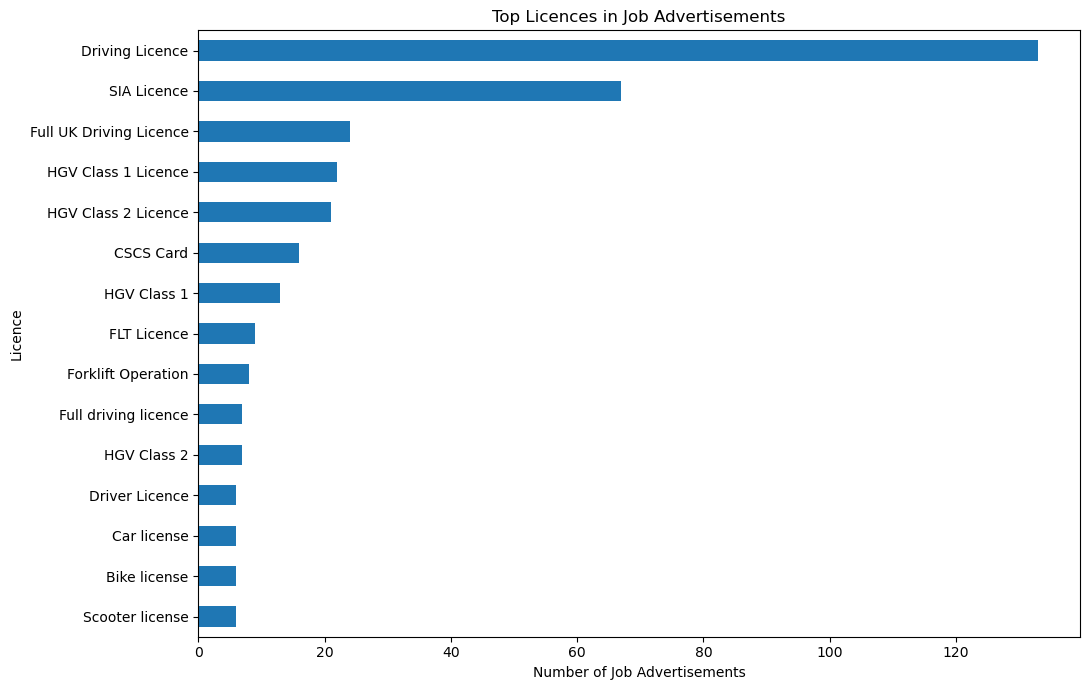

In [20]:
# ============================================================
# TOP LICENCES VISUALISATION
# ============================================================

top_licenses = license_counts.head(15).sort_values()

plt.figure(figsize=(11, 7))

top_licenses.plot(kind="barh")

plt.title("Top Licences in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Licence")

plt.tight_layout()
plt.show()

In [21]:
# ============================================================
# LANGUAGE DEMAND
# ============================================================

df["languages_parsed"] = df[
    "languages_normalized"
].apply(parse_skill_list)

language_counts_dict = {}

for languages in df["languages_parsed"]:
    for language in languages:
        if isinstance(language, str):
            language = language.strip()

            if language:
                language_counts_dict[language] = (
                    language_counts_dict.get(language, 0) + 1
                )

language_counts = (
    pd.Series(language_counts_dict)
    .sort_values(ascending=False)
)

print("=" * 70)
print("TOP LANGUAGES")
print("=" * 70)

print(language_counts.head(30))

TOP LANGUAGES
French                            54
Spanish                           34
English                           27
German                            23
Chinese                           16
Italian                           14
Japanese                          10
Arabic                             9
Portuguese                         9
Mandarin                           7
Polish                             4
Fluent English                     2
Russian                            2
Latin                              1
Fluent Ukrainian                   1
Math                               1
Additional Language Capability     1
Keen to Speak                      1
Fluent Japanese                    1
Greek                              1
Basic level English                1
Swahili                            1
Good spoken written English        1
European language                  1
Scottish                           1
English - Spoken, Written          1
Mandarin (Native level) 

In [22]:
# ============================================================
# LANGUAGE COVERAGE
# ============================================================

language_jobs = (
    df["languages_parsed"]
    .apply(len)
    .gt(0)
    .sum()
)

print("=" * 70)
print("LANGUAGE COVERAGE")
print("=" * 70)

print(
    f"Jobs containing at least one language: "
    f"{language_jobs:,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{language_jobs / len(df) * 100:.2f}%"
)

print("\nTop 20 languages:")

display(
    language_counts
    .head(20)
    .rename("job_count")
    .to_frame()
)

LANGUAGE COVERAGE
Jobs containing at least one language: 200 / 19,207
Coverage: 1.04%

Top 20 languages:


,job_count
French,54
Spanish,34
English,27
German,23
Chinese,16
Italian,14
Japanese,10
Arabic,9
Portuguese,9
Mandarin,7


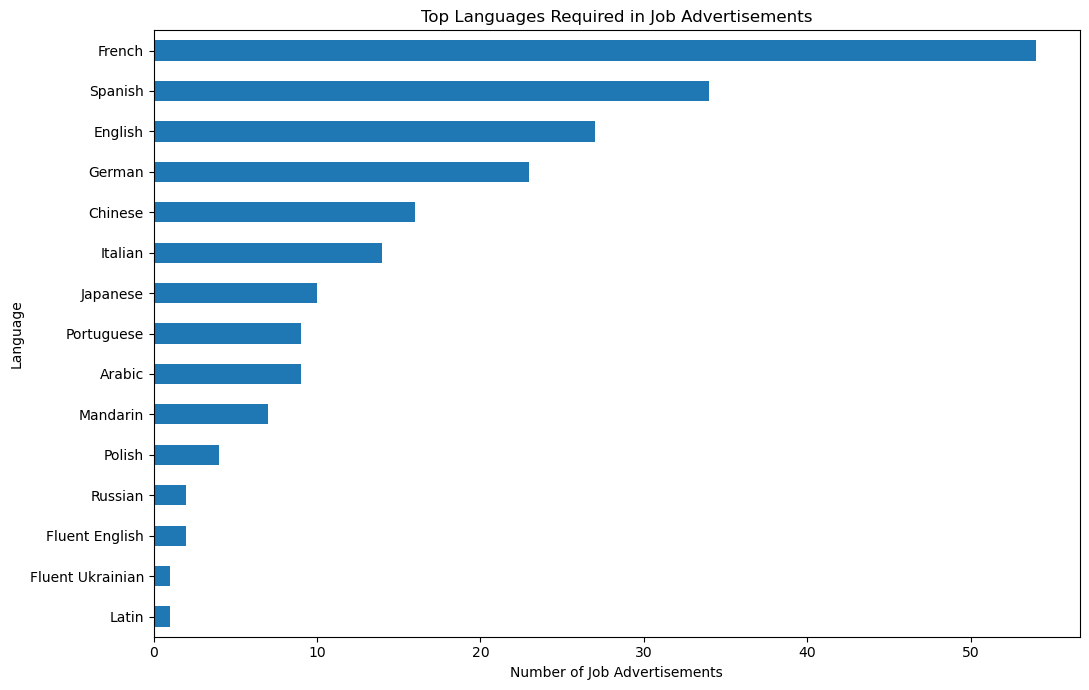

In [23]:
# ============================================================
# TOP LANGUAGES VISUALISATION
# ============================================================

top_languages = language_counts.head(15).sort_values()

plt.figure(figsize=(11, 7))

top_languages.plot(kind="barh")

plt.title("Top Languages Required in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Language")

plt.tight_layout()
plt.show()

In [24]:
# ============================================================
# EDUCATION REQUIREMENT ANALYSIS
# ============================================================

education_series = (
    df["education_required"]
    .fillna("")
    .astype(str)
    .str.strip()
)

education_non_empty = education_series[
    education_series != ""
]

print("=" * 70)
print("EDUCATION REQUIREMENTS")
print("=" * 70)

print(
    f"Jobs with education information: "
    f"{len(education_non_empty):,} / {len(df):,}"
)

print(
    f"Coverage: "
    f"{len(education_non_empty) / len(df) * 100:.2f}%"
)

print("\nMost common education requirements:")

display(
    education_non_empty
    .value_counts()
    .head(30)
    .rename("job_count")
    .to_frame()
)

EDUCATION REQUIREMENTS
Jobs with education information: 1,453 / 19,207
Coverage: 7.56%

Most common education requirements:


,job_count
education_required,
Formal teaching experience,125
[],80
not specified,69
Bachelor's degree,69
Not explicitly stated,59
Graduate,53
graduate,31
not explicitly stated,28
Qualified Accountant,20


In [25]:
# ============================================================
# EDUCATION LEVEL KEYWORD ANALYSIS
# ============================================================

education_text = (
    education_series
    .str.lower()
)

education_levels = {
    "Degree": r"\bdegree\b|\bbachelor\b|\bmasters?\b|\bundergraduate\b|\bgraduate\b",
    "PhD": r"\bphd\b|\bdoctorate\b",
    "A Level": r"\ba[- ]?level\b",
    "GCSE": r"\bgcse\b",
    "NVQ": r"\bnvq\b",
    "HND/HNC": r"\bhnd\b|\bhnc\b",
    "Apprenticeship": r"\bapprenticeship\b|\bapprentice\b",
    "Diploma": r"\bdiploma\b",
    "Professional Qualification": r"\bprofessional qualification\b|\bprofessional certification\b",
}

education_level_counts = {}

for level, pattern in education_levels.items():
    count = education_text.str.contains(
        pattern,
        regex=True,
        na=False
    ).sum()
    
    education_level_counts[level] = count

education_level_counts = (
    pd.Series(education_level_counts)
    .sort_values(ascending=False)
)

print("=" * 70)
print("EDUCATION LEVEL INDICATORS")
print("=" * 70)

display(
    education_level_counts
    .rename("job_count")
    .to_frame()
)

EDUCATION LEVEL INDICATORS


,job_count
Degree,312
Apprenticeship,31
Diploma,11
NVQ,9
HND/HNC,9
PhD,3
A Level,0
GCSE,0
Professional Qualification,0


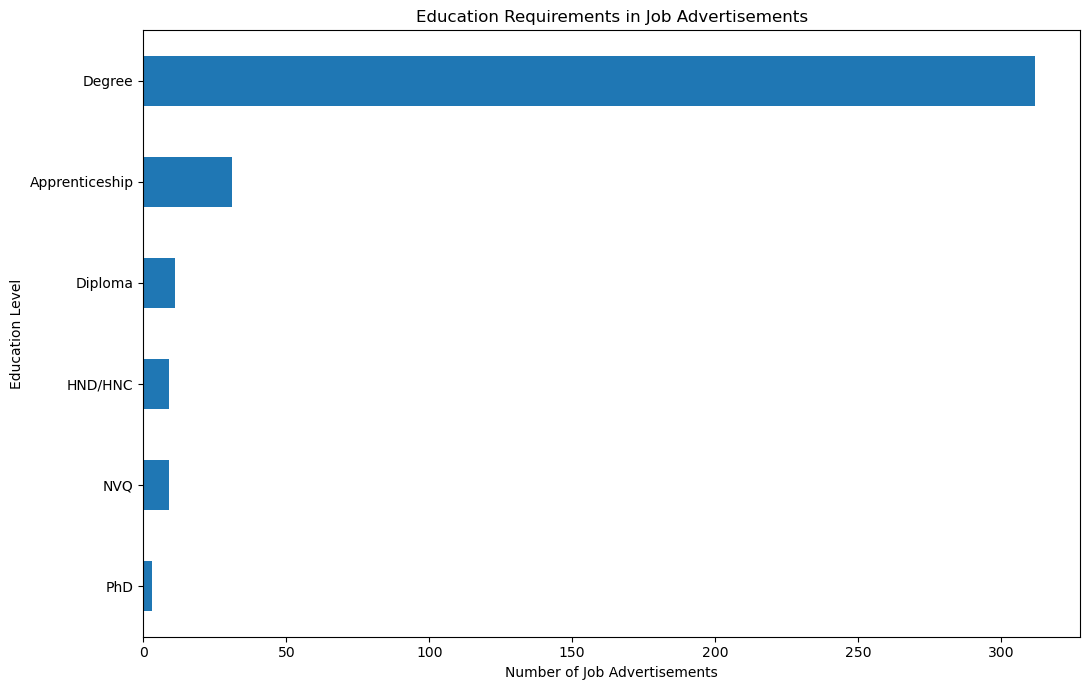

In [26]:
# ============================================================
# EDUCATION LEVEL VISUALISATION
# ============================================================

education_chart = education_level_counts[
    education_level_counts > 0
].sort_values()

plt.figure(figsize=(11, 7))

education_chart.plot(kind="barh")

plt.title("Education Requirements in Job Advertisements")
plt.xlabel("Number of Job Advertisements")
plt.ylabel("Education Level")

plt.tight_layout()
plt.show()

In [27]:
# ============================================================
# FINAL EXPERIENCE NORMALISATION
# ============================================================

import re
import numpy as np

print("=" * 70)
print("FINAL EXPERIENCE NORMALISATION")
print("=" * 70)

# Preserve original LLM extraction
if "experience_required_original" not in df.columns:
    df["experience_required_original"] = df["experience_required"]

def clean_experience_text(value):
    if pd.isna(value):
        return ""
    if isinstance(value, list):
        value = " ".join(str(x) for x in value)
    value = str(value).strip()
    if value.lower() in ["", "[]", "nan", "none", "not specified", "not explicitly stated"]:
        return ""
    value = value.replace("[", "").replace("]", "")
    value = re.sub(r"\s+", " ", value)
    return value.strip()

df["experience_clean"] = df["experience_required"].apply(clean_experience_text)

def extract_years(text):
    if not text:
        return np.nan
    text = text.lower()

    # Explicit year requirements
    match = re.search(r"(\d+(?:\.\d+)?)\s*(?:\+\s*)?(?:years?|yrs?)", text)
    if match:
        return float(match.group(1))

    # Explicit month requirements converted to years
    match = re.search(r"(\d+(?:\.\d+)?)\s*(?:months?|mos?)", text)
    if match:
        return float(match.group(1)) / 12

    return np.nan

df["experience_years"] = df["experience_clean"].apply(extract_years)

def classify_experience_final(text, years):
    text = text.lower().strip()

    if not text:
        return "Not Specified"

    # Numeric experience takes priority
    if pd.notna(years):
        if years <= 0:
            return "Entry / No Experience"
        elif years < 1:
            return "Less than 1 Year"
        elif years <= 2:
            return "1–2 Years"
        elif years <= 5:
            return "3–5 Years"
        else:
            return "5+ Years"

    # Explicit entry-level/no-experience language
    if re.search(r"\bno experience\b|\bwithout experience\b|\bentry[- ]level\b|\bno prior experience\b", text):
        return "Entry / No Experience"

    # Senior/extensive experience language
    if re.search(r"\bsenior\b|\bextensive experience\b|\bsignificant experience\b|\bsubstantial experience\b|\bconsiderable experience\b", text):
        return "Senior / Extensive Experience"

    # Qualitative experience requirements
    if re.search(
        r"\bexperienced\b|\bprevious experience\b|\bprior experience\b|\bprevious .* experience\b|"
        r"\bprior .* experience\b|\bmanagement experience\b|\brelevant experience\b|"
        r"\bprofessional experience\b|\bexperience required\b|\bexperience in\b|"
        r"\bexperience with\b|\bexperience of\b|\bexperience as\b|\bexperience working\b|"
        r"\bdepending on experience\b|\bdepending experience\b|\bexperience$|\bexperience needed\b",
        text
    ):
        return "Experience Required"

    # Preserve uncertain/other experience-related wording as experience required
    if "experience" in text:
        return "Experience Required"

    return "Not Specified"

df["experience_category_final"] = df.apply(
    lambda row: classify_experience_final(row["experience_clean"], row["experience_years"]),
    axis=1
)

# Flag unusually large numeric requirements for review; do not remove them.
df["experience_outlier_flag"] = np.where(
    df["experience_years"].notna() & (df["experience_years"] > 10),
    "Potential Outlier",
    "Normal / Not Numeric"
)

print("Jobs:", len(df))
print("Numeric experience extracted:", df["experience_years"].notna().sum())
print("Numeric coverage: {:.2f}%".format(df["experience_years"].notna().mean() * 100))
print("Potential numeric outliers (>10 years):", (df["experience_outlier_flag"] == "Potential Outlier").sum())

print("\nFinal experience categories:")
display(
    df["experience_category_final"]
    .value_counts(dropna=False)
    .rename("job_count")
    .to_frame()
)

print("\nSample:")
display(
    df[[
        "experience_required_original",
        "experience_clean",
        "experience_years",
        "experience_category_final",
        "experience_outlier_flag"
    ]].head(30)
)


FINAL EXPERIENCE NORMALISATION
Jobs: 19207
Numeric experience extracted: 1877
Numeric coverage: 9.77%
Potential numeric outliers (>10 years): 3

Final experience categories:


,job_count
experience_category_final,
Not Specified,12703
Experience Required,4401
1–2 Years,1835
Senior / Extensive Experience,200
Entry / No Experience,31
Less than 1 Year,25
5+ Years,7
3–5 Years,5



Sample:


,experience_required_original,experience_clean,experience_years,experience_category_final,experience_outlier_flag
0,Qualified dispenser pharmacy experience,Qualified dispenser pharmacy experience,NaN,Experience Required,Normal / Not Numeric
1,NaN,,NaN,Not Specified,Normal / Not Numeric
2,NaN,,NaN,Not Specified,Normal / Not Numeric
3,2 years of experience,2 years of experience,2.0,1–2 Years,Normal / Not Numeric
4,NaN,,NaN,Not Specified,Normal / Not Numeric
5,[],,NaN,Not Specified,Normal / Not Numeric
6,NaN,,NaN,Not Specified,Normal / Not Numeric
7,2 years of experience,2 years of experience,2.0,1–2 Years,Normal / Not Numeric
8,NaN,,NaN,Not Specified,Normal / Not Numeric
9,NaN,,NaN,Not Specified,Normal / Not Numeric


In [28]:
# ============================================================
# FINAL EXPERIENCE × INDUSTRY
# ============================================================

print("=" * 70)
print("FINAL EXPERIENCE × INDUSTRY")
print("=" * 70)

experience_industry_df = df[
    df["experience_category_final"].notna()
][["industry", "experience_category_final"]].copy()

experience_industry_df = experience_industry_df.rename(
    columns={"experience_category_final": "experience_category"}
)

experience_industry_counts = (
    experience_industry_df
    .groupby(["industry", "experience_category"])
    .size()
    .reset_index(name="job_count")
)

experience_industry_counts["percentage"] = (
    experience_industry_counts
    .groupby("industry")["job_count"]
    .transform(lambda x: x / x.sum() * 100)
)

print("Experience-industry records:", len(experience_industry_df))
print("\nTop experience categories by industry:")

for industry in sorted(experience_industry_counts["industry"].unique()):
    temp = experience_industry_counts[
        experience_industry_counts["industry"] == industry
    ].sort_values("job_count", ascending=False)

    print("\n" + "-" * 70)
    print(industry)
    display(temp.head(10))


FINAL EXPERIENCE × INDUSTRY
Experience-industry records: 19207

Top experience categories by industry:

----------------------------------------------------------------------
Automotive


,industry,experience_category,job_count,percentage
2,Automotive,Not Specified,153,64.016736
1,Automotive,Experience Required,63,26.359833
0,Automotive,1–2 Years,23,9.623431



----------------------------------------------------------------------
Construction


,industry,experience_category,job_count,percentage
6,Construction,Not Specified,671,57.155026
5,Construction,Experience Required,455,38.756388
3,Construction,1–2 Years,44,3.747871
7,Construction,Senior / Extensive Experience,3,0.255537
4,Construction,Entry / No Experience,1,0.085179



----------------------------------------------------------------------
Education


,industry,experience_category,job_count,percentage
11,Education,Not Specified,637,63.827655
10,Education,Experience Required,314,31.462926
8,Education,1–2 Years,45,4.509018
9,Education,3–5 Years,1,0.100200
12,Education,Senior / Extensive Experience,1,0.100200


... (24 outputs left out)


----------------------------------------------------------------------
Retail


,industry,experience_category,job_count,percentage
82,Retail,Not Specified,117,61.904762
81,Retail,Experience Required,39,20.634921
79,Retail,1–2 Years,31,16.402116
80,Retail,Entry / No Experience,1,0.529101
83,Retail,Senior / Extensive Experience,1,0.529101



----------------------------------------------------------------------
Transport and Logistics


,industry,experience_category,job_count,percentage
87,Transport and Logistics,Not Specified,532,60.869565
85,Transport and Logistics,Experience Required,230,26.315789
84,Transport and Logistics,1–2 Years,104,11.899314
86,Transport and Logistics,Less than 1 Year,6,0.686499
88,Transport and Logistics,Senior / Extensive Experience,2,0.228833


In [29]:
# ============================================================
# ROBUST NUMERIC EXPERIENCE BY INDUSTRY
# ============================================================

print("=" * 70)
print("ROBUST NUMERIC EXPERIENCE BY INDUSTRY")
print("=" * 70)

numeric_experience_df = df[
    df["experience_years"].notna()
][["industry", "experience_years"]].copy()

numeric_experience_by_industry = (
    numeric_experience_df
    .groupby("industry")["experience_years"]
    .agg(
        job_count="count",
        mean_years="mean",
        median_years="median",
        minimum_years="min",
        maximum_years="max",
        q1_years=lambda x: x.quantile(0.25),
        q3_years=lambda x: x.quantile(0.75)
    )
)

numeric_experience_by_industry["iqr_years"] = (
    numeric_experience_by_industry["q3_years"] -
    numeric_experience_by_industry["q1_years"]
)

numeric_experience_by_industry = numeric_experience_by_industry.sort_values(
    "median_years", ascending=False
)

print("Numeric experience records:", len(numeric_experience_df))
print("\nRobust numeric experience statistics by industry:")
display(numeric_experience_by_industry.round(2))

print("\nNote: median and IQR are preferred for interpretation because some industries contain unusually high extracted values. Extreme values are retained and flagged rather than automatically removed.")


ROBUST NUMERIC EXPERIENCE BY INDUSTRY
Numeric experience records: 1877

Robust numeric experience statistics by industry:


,job_count,mean_years,median_years,minimum_years,maximum_years,q1_years,q3_years,iqr_years
industry,,,,,,,,
IT and Technology,18,1.28,2.0,0.00,2.0,0.25,2.0,1.75
Construction,44,1.95,2.0,1.00,2.0,2.00,2.0,0.00
Retail,31,2.00,2.0,2.00,2.0,2.00,2.0,0.00
Other,1020,2.00,2.0,0.08,20.0,2.00,2.0,0.00
Marketing and Advertising,12,1.75,2.0,1.00,2.0,1.75,2.0,0.25
Manufacturing,138,1.92,2.0,0.08,3.0,2.00,2.0,0.00
Legal,26,2.04,2.0,1.00,5.0,2.00,2.0,0.00
Insurance,7,2.00,2.0,2.00,2.0,2.00,2.0,0.00
Transport and Logistics,110,1.88,2.0,0.08,2.0,2.00,2.0,0.00



Note: median and IQR are preferred for interpretation because some industries contain unusually high extracted values. Extreme values are retained and flagged rather than automatically removed.


In [30]:
# ============================================================
# EXPERIENCE × SALARY
# ============================================================
print("=" * 70); print("EXPERIENCE × SALARY"); print("=" * 70)
exp_salary_df=df[df["experience_category_final"].notna() & df["salary_avg"].notna()].copy()
exp_salary_df["salary_avg"]=pd.to_numeric(exp_salary_df["salary_avg"],errors="coerce")
exp_salary_df=exp_salary_df[exp_salary_df["salary_avg"]>0]
exp_salary_summary=(exp_salary_df.groupby("experience_category_final")["salary_avg"].agg(job_count="count",mean_salary="mean",median_salary="median",q1_salary=lambda x:x.quantile(.25),q3_salary=lambda x:x.quantile(.75)).sort_values("median_salary",ascending=False))
print(f"Valid experience + salary records: {len(exp_salary_df):,}")
display(exp_salary_summary.round(2))
print("\nNote: these are descriptive salary associations, not causal effects.")


EXPERIENCE × SALARY
Valid experience + salary records: 16,668


,job_count,mean_salary,median_salary,q1_salary,q3_salary
experience_category_final,,,,,
Senior / Extensive Experience,158,58023.37,57488.80,42500.00,72375.00
3–5 Years,5,55422.15,49832.63,44229.15,65000.00
1–2 Years,1568,41511.81,40000.00,29120.00,55000.00
Experience Required,3865,37004.13,38832.28,28000.00,48939.67
Entry / No Experience,31,31866.78,37500.00,26298.72,37500.00
Not Specified,11010,37161.82,37500.00,28377.25,47500.00
5+ Years,7,40431.43,29000.00,25460.00,56250.00
Less than 1 Year,24,21002.39,13730.25,12.88,37256.50



Note: these are descriptive salary associations, not causal effects.


In [31]:
# ============================================================
# SALARY ANALYSIS
# ============================================================

print("=" * 70)
print("SALARY ANALYSIS")
print("=" * 70)

salary_available = df["salary_avg"].notna().sum()

print(
    f"Jobs with salary information: "
    f"{salary_available:,} / {len(df):,}"
)

print(
    f"Salary coverage: "
    f"{salary_available / len(df) * 100:.2f}%"
)

print("\nSalary statistics:")

display(
    df["salary_avg"].describe()
)

SALARY ANALYSIS
Jobs with salary information: 16,775 / 19,207
Salary coverage: 87.34%

Salary statistics:


count     16775.000000
mean      37465.447939
std       25451.178071
min           0.000000
25%       28000.000000
50%       37500.000000
75%       48380.165000
max      500000.000000
Name: salary_avg, dtype: float64

In [32]:
# ============================================================
# SALARY QUALITY DIAGNOSTICS
# ============================================================
salary_data = pd.to_numeric(df["salary_avg"], errors="coerce")
print("=" * 70); print("SALARY QUALITY DIAGNOSTICS"); print("=" * 70)
print(f"Salary records: {salary_data.notna().sum():,} / {len(df):,}")
print(f"Missing salary: {salary_data.isna().sum():,}")
print(f"Zero salary values: {(salary_data == 0).sum():,}")
print(f"Negative salary values: {(salary_data < 0).sum():,}")
valid_salary = salary_data[salary_data > 0]
print("\nPositive salary distribution:")
display(valid_salary.describe(percentiles=[0.25,0.50,0.75,0.95,0.99]).to_frame("salary_avg"))
print("\nHighest salary values (quality check):")
display(valid_salary.sort_values(ascending=False).head(10).to_frame("salary_avg"))
print("\nNote: salary_avg is analysed as supplied. Different pay periods may exist in source adverts, so extreme values are retained and interpreted cautiously.")


SALARY QUALITY DIAGNOSTICS
Salary records: 16,775 / 19,207
Missing salary: 2,432
Zero salary values: 107
Negative salary values: 0

Positive salary distribution:


,salary_avg
count,16668.000000
mean,37705.956874
std,25354.523333
min,8.000000
25%,28405.452500
50%,37500.000000
75%,48500.000000
95%,75000.000000
99%,110000.000000
max,500000.000000



Highest salary values (quality check):


,salary_avg
1447,500000.0
2009,435000.0
8462,425000.0
15329,375000.0
442,372000.0
16182,337500.0
8079,325000.0
10947,325000.0
13100,312000.0
4310,301000.0



Note: salary_avg is analysed as supplied. Different pay periods may exist in source adverts, so extreme values are retained and interpreted cautiously.


In [33]:
# ============================================================
# SALARY BY INDUSTRY
# ============================================================

salary_by_industry = (
    df.groupby("industry")["salary_avg"]
      .agg(
          job_count="count",
          average_salary="mean",
          median_salary="median",
          minimum_salary="min",
          maximum_salary="max"
      )
      .sort_values("average_salary", ascending=False)
)

print("=" * 70)
print("SALARY BY INDUSTRY")
print("=" * 70)

display(
    salary_by_industry.round(2)
)

SALARY BY INDUSTRY


,job_count,average_salary,median_salary,minimum_salary,maximum_salary
industry,,,,,
Real Estate,34,52365.50,42250.00,24.66,225000.0
Legal,194,50918.78,46314.62,13.36,187500.0
IT and Technology,493,47937.81,41500.00,0.00,425000.0
Insurance,29,46698.77,40000.00,25.00,167500.0
Finance and Banking,925,46440.52,47500.00,0.00,221000.0
Engineering,2143,46199.03,45000.00,0.00,245000.0
Construction,1118,42585.85,45129.86,0.00,107500.0
Marketing and Advertising,108,39417.18,36240.56,13.50,137500.0
Healthcare,221,37481.88,32440.35,12.00,312000.0


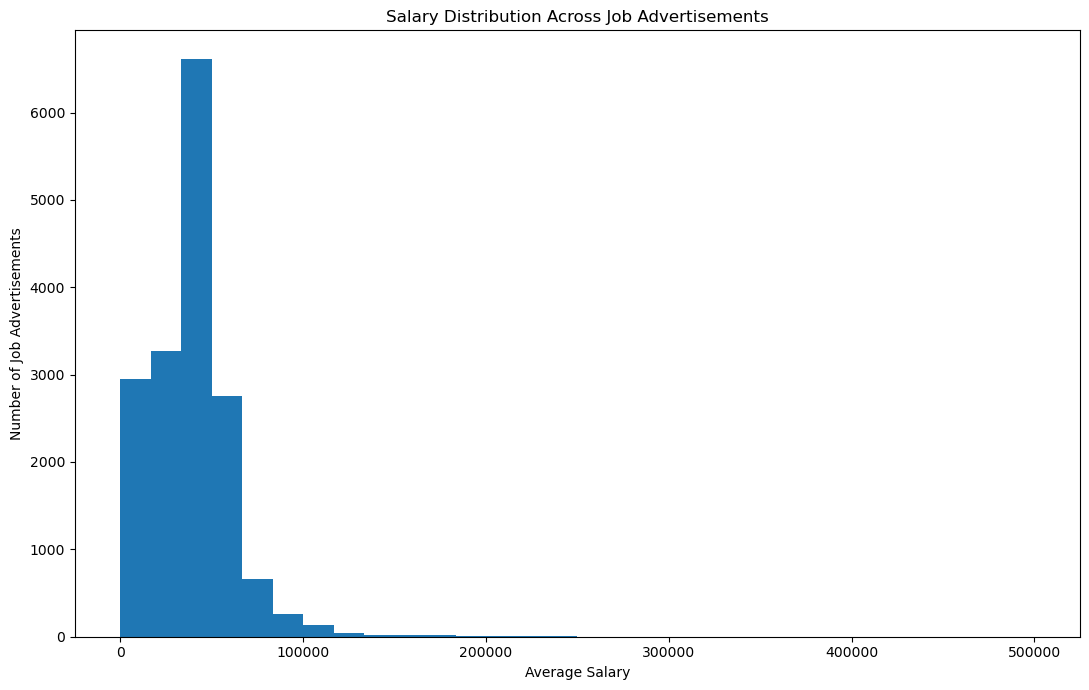

In [34]:
# ============================================================
# SALARY DISTRIBUTION
# ============================================================

salary_data = df["salary_avg"].dropna()

plt.figure(figsize=(11, 7))

plt.hist(
    salary_data,
    bins=30
)

plt.title("Salary Distribution Across Job Advertisements")
plt.xlabel("Average Salary")
plt.ylabel("Number of Job Advertisements")

plt.tight_layout()
plt.show()

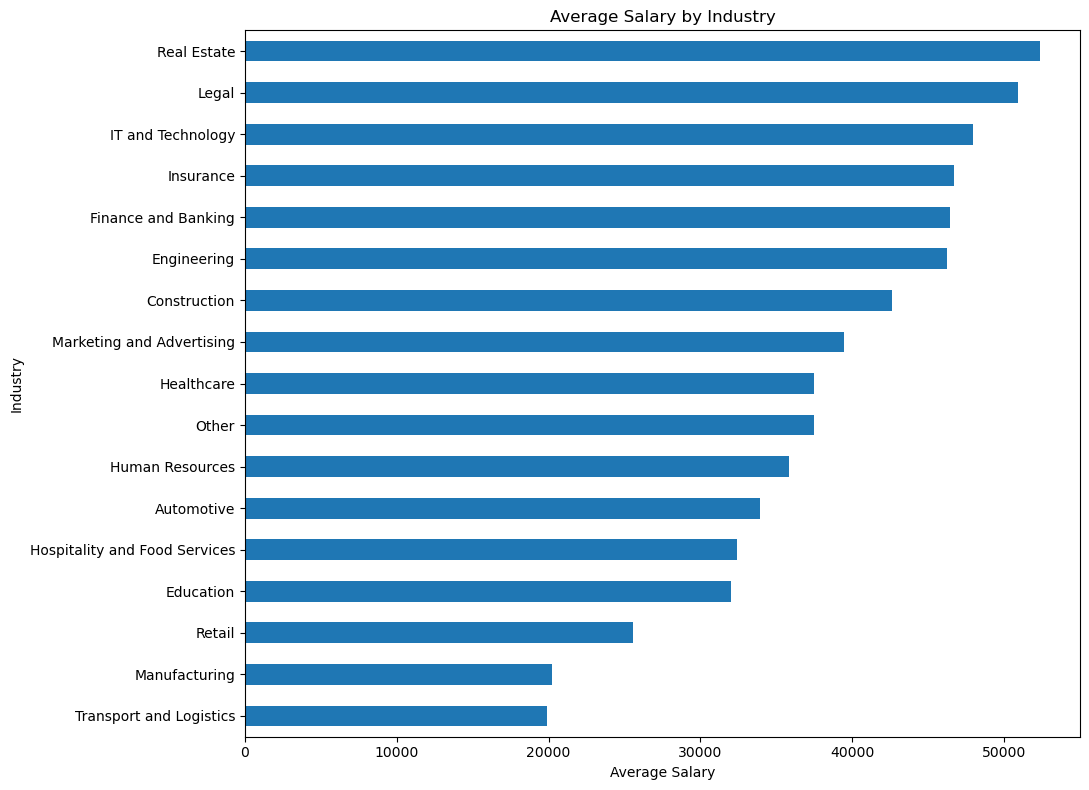

In [35]:
# ============================================================
# AVERAGE SALARY BY INDUSTRY
# ============================================================

salary_chart = (
    salary_by_industry[
        salary_by_industry["job_count"] >= 10
    ]["average_salary"]
    .sort_values()
)

plt.figure(figsize=(11, 8))

salary_chart.plot(kind="barh")

plt.title("Average Salary by Industry")
plt.xlabel("Average Salary")
plt.ylabel("Industry")

plt.tight_layout()
plt.show()

In [36]:
# ============================================================
# TECHNICAL SKILLS BY INDUSTRY
# ============================================================

print("=" * 70)
print("TECHNICAL SKILLS BY INDUSTRY")
print("=" * 70)

skill_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]

    # Use the already parsed skills column
    skills = row["technical_skills_parsed"]

    for skill in skills:

        if isinstance(skill, str):

            skill = skill.strip()

            if skill:

                skill_industry_records.append({
                    "industry": industry,
                    "skill": skill
                })


skill_industry_df = pd.DataFrame(
    skill_industry_records,
    columns=["industry", "skill"]
)

print(
    "Skill-industry records:",
    len(skill_industry_df)
)

print("\nColumns:")
print(skill_industry_df.columns.tolist())

display(
    skill_industry_df.head(20)
)

TECHNICAL SKILLS BY INDUSTRY
Skill-industry records: 5975

Columns:
['industry', 'skill']


,industry,skill
0,Construction,Electrical Installation
1,IT and Technology,C#
2,Other,Security Architecture
3,Other,Cybersecurity Strategy
4,Other,Data Analysis
5,Other,Advanced Analytics
6,Finance and Banking,Regulatory Submission Preparation
7,Other,Financial Analysis
8,Other,Budgeting
9,Other,Forecasting


In [37]:
# ============================================================
# TOP TECHNICAL SKILLS BY INDUSTRY
# ============================================================

skill_industry_counts = (
    skill_industry_df
    .groupby(["industry", "skill"])
    .size()
    .reset_index(name="job_count")
)

skill_industry_counts = (
    skill_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP TECHNICAL SKILLS BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    skill_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        skill_industry_counts[
            skill_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP TECHNICAL SKILLS BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,skill,job_count
0,Automotive,Vehicle Maintenance,9
1,Automotive,Light vehicle maintenance,4
2,Automotive,Diagnostic Skill,2
3,Automotive,Panel painting,2
4,Automotive,Repair,2
5,Automotive,Servicing,2
6,Automotive,CNC Programming,1
7,Automotive,CNC Turning,1
8,Automotive,Calibration,1
9,Automotive,Diagnostic Equipment,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,skill,job_count
0,Construction,Electrical Installation,184
1,Construction,Welding,49
2,Construction,MIG Welding,39
3,Construction,Fabrication,34
4,Construction,Carpentry,30
5,Construction,TIG Welding,29
6,Construction,Plumbing,15
7,Construction,Decorating,11
8,Construction,Painting,11
9,Construction,Joinery,10



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,skill,job_count
0,Education,CAD,2
1,Education,Electrical Installation,2
2,Education,Electronic Engineering,2
3,Education,Manufacturing Engineering,2
4,Education,Mechanical Engineering,2
5,Education,Electrical Engineering,1
6,Education,Mechatronics,1


... (20 outputs left out)


----------------------------------------------------------------------
Real Estate
----------------------------------------------------------------------


,industry,skill,job_count
0,Real Estate,Accounting,1
1,Real Estate,Financial Analysis,1
2,Real Estate,Financial Modelling,1



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,skill,job_count
0,Transport and Logistics,Forklift Operation,88
1,Transport and Logistics,Data Warehouse Architecture,1
2,Transport and Logistics,HIAB,1
3,Transport and Logistics,Inventory Logistics,1


In [38]:
# ============================================================
# TECHNICAL SKILLS × EXPERIENCE
# ============================================================
print("=" * 70); print("TECHNICAL SKILLS × EXPERIENCE"); print("=" * 70)
skill_experience_records=[]
for _,row in df.iterrows():
 category=row.get("experience_category_final"); skills=row.get("technical_skills_parsed",[])
 if not category or category=="Not Specified": continue
 if not isinstance(skills,list): skills=parse_list_column(skills)
 for skill in skills:
  if isinstance(skill,str) and skill.strip(): skill_experience_records.append((category,skill.strip()))
skill_experience_df=pd.DataFrame(skill_experience_records,columns=["experience_category","skill"])
skill_experience_counts=(skill_experience_df.groupby(["experience_category","skill"]).size().reset_index(name="job_count").sort_values(["experience_category","job_count"],ascending=[True,False]))
print(f"Skill–experience records: {len(skill_experience_df):,}")
for category in skill_experience_counts["experience_category"].drop_duplicates():
 print(f"\nTop technical skills — {category}")
 display(skill_experience_counts[skill_experience_counts["experience_category"]==category].head(10))


TECHNICAL SKILLS × EXPERIENCE
Skill–experience records: 2,275

Top technical skills — 1–2 Years


,experience_category,skill,job_count
49,1–2 Years,Electrical Installation,35
60,1–2 Years,Financial Analysis,29
61,1–2 Years,Financial Modelling,14
65,1–2 Years,Forklift Operation,9
108,1–2 Years,Project Management,7
88,1–2 Years,Mechanical Maintenance,6
50,1–2 Years,Electrical Maintenance,5
27,1–2 Years,CNC Milling,4
53,1–2 Years,Electronics Design,4
24,1–2 Years,CAD,3



Top technical skills — Experience Required


,experience_category,skill,job_count
464,Experience Required,Electrical Installation,163
546,Experience Required,Forklift Operation,43
295,Experience Required,CNC Milling,34
1063,Experience Required,Welding,34
525,Experience Required,Financial Analysis,27
664,Experience Required,MIG Welding,27
291,Experience Required,CNC Machining,25
708,Experience Required,Mechanical Engineering,24
300,Experience Required,CNC Programming,23
707,Experience Required,Mechanical Design,20



Top technical skills — Senior / Extensive Experience


,experience_category,skill,job_count
1113,Senior / Extensive Experience,Electrical Installation,6
1121,Senior / Extensive Experience,Financial Analysis,4
1141,Senior / Extensive Experience,Mechanical Engineering,3
1085,Senior / Extensive Experience,AI,2
1088,Senior / Extensive Experience,AWS,2
1094,Senior / Extensive Experience,Azure,2
1107,Senior / Extensive Experience,Design,2
1122,Senior / Extensive Experience,Financial Modelling,2
1132,Senior / Extensive Experience,Java,2
1139,Senior / Extensive Experience,Machine Learning,2


In [39]:
# ============================================================
# SOFT SKILLS BY INDUSTRY
# ============================================================

print("=" * 70)
print("SOFT SKILLS BY INDUSTRY")
print("=" * 70)

soft_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]
    skills = row["soft_skills_parsed"]

    for skill in skills:

        if isinstance(skill, str):

            skill = skill.strip()

            if skill:
                soft_industry_records.append({
                    "industry": industry,
                    "skill": skill
                })

soft_industry_df = pd.DataFrame(
    soft_industry_records,
    columns=["industry", "skill"]
)

print(
    "Soft-skill industry records:",
    len(soft_industry_df)
)

print("\nColumns:")
print(soft_industry_df.columns.tolist())

display(
    soft_industry_df.head(20)
)

SOFT SKILLS BY INDUSTRY
Soft-skill industry records: 16450

Columns:
['industry', 'skill']


,industry,skill
0,Other,Communication
1,Other,Teamwork
2,Other,Problem Solving
3,Other,Attention to Detail
4,Other,Time Management
5,Retail,Leadership
6,Retail,Teamwork
7,Retail,Communication
8,Retail,Problem Solving
9,Retail,Attention to Detail


In [40]:
# ============================================================
# TOP SOFT SKILLS BY INDUSTRY
# ============================================================

soft_industry_counts = (
    soft_industry_df
    .groupby(["industry", "skill"])
    .size()
    .reset_index(name="job_count")
)

soft_industry_counts = (
    soft_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP SOFT SKILLS BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    soft_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        soft_industry_counts[
            soft_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP SOFT SKILLS BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,skill,job_count
0,Automotive,Customer Service,14
1,Automotive,Flexibility,9
2,Automotive,Communication,7
3,Automotive,Problem Solving,7
4,Automotive,Teamwork,6
5,Automotive,Attention to Detail,5
6,Automotive,Adaptability,3
7,Automotive,Confident,1
8,Automotive,Innovation,1
9,Automotive,Organisation,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,skill,job_count
0,Construction,Communication,43
1,Construction,Problem Solving,41
2,Construction,Attention to Detail,35
3,Construction,Teamwork,32
4,Construction,Leadership,28
5,Construction,Reliable,16
6,Construction,Reliability,10
7,Construction,Project Management,7
8,Construction,Time Management,7
9,Construction,Customer Service,6



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,skill,job_count
0,Education,Communication,366
1,Education,Problem Solving,153
2,Education,Listening,104
3,Education,Teamwork,100
4,Education,Attention to Detail,87
5,Education,Enthusiasm,49
6,Education,Leadership,43
7,Education,Time Management,37
8,Education,Interest in helping students succeed,35
9,Education,Passion,35


... (24 outputs left out)


----------------------------------------------------------------------
Retail
----------------------------------------------------------------------


,industry,skill,job_count
0,Retail,Customer Service,96
1,Retail,Problem Solving,62
2,Retail,Teamwork,62
3,Retail,Communication,56
4,Retail,Leadership,51
5,Retail,Attention to Detail,37
6,Retail,Time Management,21
7,Retail,Flexibility,10
8,Retail,Sociability,3
9,Retail,Motivated,2



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,skill,job_count
0,Transport and Logistics,Attention to Detail,95
1,Transport and Logistics,Teamwork,83
2,Transport and Logistics,Problem Solving,76
3,Transport and Logistics,Leadership,72
4,Transport and Logistics,Communication,65
5,Transport and Logistics,Customer Service,36
6,Transport and Logistics,Reliable,30
7,Transport and Logistics,Time Management,20
8,Transport and Logistics,Reliability,15
9,Transport and Logistics,Hardworking,9


In [41]:
# ============================================================
# PARSE TOOLS & TECHNOLOGIES
# ============================================================

import ast
import pandas as pd

def parse_list_column(value):
    """
    Convert a CSV string representation of a list
    into an actual Python list.
    """
    
    if pd.isna(value):
        return []
    
    if isinstance(value, list):
        return value
    
    try:
        parsed = ast.literal_eval(str(value))
        
        if isinstance(parsed, list):
            return parsed
        
        return []
    
    except (ValueError, SyntaxError):
        return []


df["tools_and_technologies_parsed"] = (
    df["tools_and_technologies"]
    .apply(parse_list_column)
)

print("=" * 70)
print("TOOLS & TECHNOLOGIES PARSING")
print("=" * 70)

print(
    "Jobs:",
    len(df)
)

print(
    "Parsed column created:",
    "tools_and_technologies_parsed" in df.columns
)

print("\nExample parsed values:")

display(
    df[
        [
            "title",
            "tools_and_technologies",
            "tools_and_technologies_parsed"
        ]
    ].head(10)
)

TOOLS & TECHNOLOGIES PARSING
Jobs: 19207
Parsed column created: True

Example parsed values:


,title,tools_and_technologies,tools_and_technologies_parsed
0,Dispenser NVQ,[],[]
1,Service Colleague Express,[],[]
2,Service Colleague Express,[],[]
3,Customer Delivery Driver,[],[]
4,IT Security Technical Delivery Manager VP,[],[]
5,Career Starter Stores,[],[]
6,Pharmacy Colleague,[],[]
7,Store Manager,[],[]
8,Greggs Service Colleague Food Services,[],[]
9,CASS Oversight Analyst - 12mth FTC - M&G plc.,[],[]


In [42]:
# ============================================================
# TOOLS & TECHNOLOGIES BY INDUSTRY
# ============================================================

print("=" * 70)
print("TOOLS & TECHNOLOGIES BY INDUSTRY")
print("=" * 70)

tools_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]
    tools = row["tools_and_technologies_parsed"]

    for tool in tools:

        if isinstance(tool, str):

            tool = tool.strip()

            if tool:
                tools_industry_records.append({
                    "industry": industry,
                    "tool": tool
                })


tools_industry_df = pd.DataFrame(
    tools_industry_records,
    columns=["industry", "tool"]
)

print(
    "Tool-industry records:",
    len(tools_industry_df)
)

print("\nColumns:")
print(tools_industry_df.columns.tolist())

display(
    tools_industry_df.head(20)
)

TOOLS & TECHNOLOGIES BY INDUSTRY
Tool-industry records: 1178

Columns:
['industry', 'tool']


,industry,tool
0,Transport and Logistics,Forklift Operation
1,Other,Microsoft Excel
2,IT and Technology,Electrical installation
3,Other,tool time
4,Engineering,Van
5,Engineering,Fuel Card
6,Engineering,Tech Package
7,Other,Microsoft Copilot
8,Other,AWS OpenSearch
9,Other,Terraform


In [43]:
# ============================================================
# TOP TOOLS & TECHNOLOGIES BY INDUSTRY
# ============================================================

tools_industry_counts = (
    tools_industry_df
    .groupby(["industry", "tool"])
    .size()
    .reset_index(name="job_count")
)

tools_industry_counts = (
    tools_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP TOOLS & TECHNOLOGIES BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    tools_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        tools_industry_counts[
            tools_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP TOOLS & TECHNOLOGIES BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,tool,job_count
0,Automotive,Autel,1
1,Automotive,ISTA,1
2,Automotive,Latest Facility,1
3,Automotive,ODIS VCDs,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,tool,job_count
0,Construction,CNC Programming,1
1,Construction,CostX,1
2,Construction,First Aid,1
3,Construction,Hand Power Tools,1
4,Construction,Hand Tools,1
5,Construction,IPAF,1
6,Construction,MEWPS,1
7,Construction,MIG,1
8,Construction,MMA Stick,1
9,Construction,Machinery,1



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,tool,job_count
0,Education,Online Lesson,2
1,Education,AI,1
2,Education,Coding,1
3,Education,Computer Science,1
4,Education,Computing department,1
5,Education,Full time,1
6,Education,Microsoft Excel,1
7,Education,Online Tutoring Platform,1
8,Education,Online lesson platform,1
9,Education,Online lesson search,1


... (22 outputs left out)


----------------------------------------------------------------------
Retail
----------------------------------------------------------------------


,industry,tool,job_count
0,Retail,Microsoft Excel,1
1,Retail,Point of Sale (POS),1



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,tool,job_count
0,Transport and Logistics,Forklift,7
1,Transport and Logistics,Forklift Operation,6
2,Transport and Logistics,SAP,3
3,Transport and Logistics,Side Loader,2
4,Transport and Logistics,Barcoding,1
5,Transport and Logistics,Bendi Flexi Forklift,1
6,Transport and Logistics,Bendi flexi forklift truck,1
7,Transport and Logistics,Bicycle,1
8,Transport and Logistics,CNC machine,1
9,Transport and Logistics,CPC,1


In [44]:
# ============================================================
# CERTIFICATIONS BY INDUSTRY
# ============================================================

print("=" * 70)
print("CERTIFICATIONS BY INDUSTRY")
print("=" * 70)

cert_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]
    certifications = row["certifications"]

    for cert in parse_list_column(certifications):

        if isinstance(cert, str):

            cert = cert.strip()

            if cert:
                cert_industry_records.append({
                    "industry": industry,
                    "certification": cert
                })


cert_industry_df = pd.DataFrame(
    cert_industry_records,
    columns=["industry", "certification"]
)

print(
    "Certification-industry records:",
    len(cert_industry_df)
)

print("\nColumns:")
print(cert_industry_df.columns.tolist())

display(
    cert_industry_df.head(20)
)

CERTIFICATIONS BY INDUSTRY
Certification-industry records: 517

Columns:
['industry', 'certification']


,industry,certification
0,Healthcare,NVQ
1,Other,Retailer qualification
2,Other,SVQ
3,Healthcare,Care Certificate
4,Healthcare,Blue Light Card
5,Other,ACCA
6,Other,CPCS
7,Other,NPORS
8,Other,NMC HCPC Professional Eligible
9,Engineering,relevant certification documentation


In [45]:
# ============================================================
# TOP CERTIFICATIONS BY INDUSTRY
# ============================================================

cert_industry_counts = (
    cert_industry_df
    .groupby(["industry", "certification"])
    .size()
    .reset_index(name="job_count")
)

cert_industry_counts = (
    cert_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP CERTIFICATIONS BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    cert_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        cert_industry_counts[
            cert_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP CERTIFICATIONS BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,certification,job_count
0,Automotive,NVQ,2
1,Automotive,NVQ level City & Guild qualification equivalent,1
2,Automotive,TH Edition Holder,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,certification,job_count
0,Construction,Approved Electrician,1
1,Construction,Basic DB Asbestos awareness,1
2,Construction,CCDO Demolition Manager Card,1
3,Construction,CSCS,1
4,Construction,CSCS Card,1
5,Construction,CSCS Skill Card,1
6,Construction,Chartered Building Surveyor,1
7,Construction,Coded TIG Welder,1
8,Construction,EC certification,1
9,Construction,ECS Gold Card,1



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,certification,job_count
0,Education,QTS,8
1,Education,HNC Childhood Practice,1
2,Education,Qualified Teacher Status (QTS),1
3,Education,SCQF Level,1
4,Education,SVQ Child Care Education,1
5,Education,SVQ Early Year,1
6,Education,SVQ Social Service Child Young People SCQF Equ...,1
7,Education,Special Educational Need Teaching Assistant Card,1


... (20 outputs left out)


----------------------------------------------------------------------
Real Estate
----------------------------------------------------------------------


,industry,certification,job_count
0,Real Estate,ACA,1
1,Real Estate,ACCA,1
2,Real Estate,CIMA,1



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,certification,job_count
0,Transport and Logistics,CPC,3
1,Transport and Logistics,Digital Tachograph Card,2
2,Transport and Logistics,Driving Licence,2
3,Transport and Logistics,Valid reach forklift licence,2
4,Transport and Logistics,ADR,1
5,Transport and Logistics,Accredited licence,1
6,Transport and Logistics,C1 License,1
7,Transport and Logistics,CE Licence,1
8,Transport and Logistics,CPC Card,1
9,Transport and Logistics,CPC card,1


In [46]:
# ============================================================
# LICENCES BY INDUSTRY
# ============================================================

print("=" * 70)
print("LICENCES BY INDUSTRY")
print("=" * 70)

licence_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]
    licences = row["licenses"]

    for licence in parse_list_column(licences):

        if isinstance(licence, str):

            licence = licence.strip()

            if licence:
                licence_industry_records.append({
                    "industry": industry,
                    "licence": licence
                })


licence_industry_df = pd.DataFrame(
    licence_industry_records,
    columns=["industry", "licence"]
)

print(
    "Licence-industry records:",
    len(licence_industry_df)
)

print("\nColumns:")
print(licence_industry_df.columns.tolist())

display(
    licence_industry_df.head(20)
)

LICENCES BY INDUSTRY
Licence-industry records: 584

Columns:
['industry', 'licence']


,industry,licence
0,Transport and Logistics,Driving Licence
1,Transport and Logistics,Driving Licence
2,Other,HGV Class 2
3,Transport and Logistics,Driving Licence
4,Transport and Logistics,SIA Licence
5,Transport and Logistics,HGV Cat. D
6,Transport and Logistics,valid ppt licence
7,Other,Full UK Driving Licence
8,Transport and Logistics,Valid Driver License
9,Transport and Logistics,SIA Licence


In [47]:
# ============================================================
# TOP LICENCES BY INDUSTRY
# ============================================================

licence_industry_counts = (
    licence_industry_df
    .groupby(["industry", "licence"])
    .size()
    .reset_index(name="job_count")
)

licence_industry_counts = (
    licence_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP LICENCES BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    licence_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        licence_industry_counts[
            licence_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP LICENCES BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,licence,job_count
0,Automotive,Full valid driving licence,1
1,Automotive,SIA Licence,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,licence,job_count
0,Construction,SIA Licence,3
1,Construction,Driving Licence,2
2,Construction,CPCs,1
3,Construction,CSCS,1
4,Construction,CSCS Card,1
5,Construction,Full Driving Licence,1
6,Construction,Full UK driving license,1
7,Construction,NPORS,1
8,Construction,Test and Inspection,1



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,licence,job_count
0,Education,Driving Licence,1
1,Education,Valid UK driver license,1


... (18 outputs left out)


----------------------------------------------------------------------
Retail
----------------------------------------------------------------------


,industry,licence,job_count
0,Retail,Full UK driving licence,1



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,licence,job_count
0,Transport and Logistics,Driving Licence,56
1,Transport and Logistics,SIA Licence,44
2,Transport and Logistics,HGV Class 1 Licence,20
3,Transport and Logistics,HGV Class 2 Licence,17
4,Transport and Logistics,HGV Class 1,8
5,Transport and Logistics,CSCS Card,6
6,Transport and Logistics,Forklift Operation,6
7,Transport and Logistics,HGV Licence,6
8,Transport and Logistics,C1,4
9,Transport and Logistics,HGV Driver Licence,4


In [48]:
# ============================================================
# EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

print("=" * 70)
print("EDUCATION REQUIREMENTS BY INDUSTRY")
print("=" * 70)

education_industry_records = []

for _, row in df.iterrows():

    industry = row["industry"]
    education = row["education_required"]

    # Skip missing values
    if pd.isna(education):
        continue

    # Convert to string
    education = str(education).strip()

    # Skip empty / meaningless values
    if education in ["", "[]", "nan", "None"]:
        continue

    # Handle list-like values
    if education.startswith("[") and education.endswith("]"):

        try:
            parsed = ast.literal_eval(education)

            if isinstance(parsed, list):
                for item in parsed:

                    if pd.isna(item):
                        continue

                    item = str(item).strip()

                    if item:
                        education_industry_records.append(
                            {
                                "industry": industry,
                                "education": item
                            }
                        )

            else:
                education_industry_records.append(
                    {
                        "industry": industry,
                        "education": education
                    }
                )

        except Exception:

            education_industry_records.append(
                {
                    "industry": industry,
                    "education": education
                }
            )

    else:

        education_industry_records.append(
            {
                "industry": industry,
                "education": education
            }
        )


education_industry_df = pd.DataFrame(
    education_industry_records
)

print(
    "Education-industry records:",
    len(education_industry_df)
)

print("\nColumns:")
print(education_industry_df.columns.tolist())

display(
    education_industry_df.head(20)
)

EDUCATION REQUIREMENTS BY INDUSTRY
Education-industry records: 1375

Columns:
['industry', 'education']


,industry,education
0,Healthcare,Nursery Practitioner Level 3
1,Healthcare,qualified audiologist
2,Healthcare,Qualification
3,Other,Diploma equivalent
4,Other,Diploma equivalent
5,Finance and Banking,Apprentice
6,Healthcare,paediatric occupational therapist
7,Healthcare,Level 2
8,Healthcare,Level 3
9,Other,"Diploma in Social Work, Degree in Social Work"


In [49]:
# ============================================================
# TOP EDUCATION REQUIREMENTS BY INDUSTRY
# ============================================================

education_industry_counts = (
    education_industry_df
    .groupby(["industry", "education"])
    .size()
    .reset_index(name="job_count")
)

education_industry_counts = (
    education_industry_counts
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
)

print("=" * 70)
print("TOP EDUCATION REQUIREMENTS BY INDUSTRY")
print("=" * 70)

for industry in sorted(
    education_industry_counts["industry"].unique()
):

    print("\n" + "-" * 70)
    print(industry)
    print("-" * 70)

    display(
        education_industry_counts[
            education_industry_counts["industry"] == industry
        ]
        .head(10)
        .reset_index(drop=True)
    )

TOP EDUCATION REQUIREMENTS BY INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,industry,education,job_count
0,Automotive,Level Qualified Mechanic,1
1,Automotive,higher education,1
2,Automotive,qualification,1
3,Automotive,qualification equivalent to level 2 in light v...,1
4,Automotive,qualification equivalent to light vehicle main...,1



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,industry,education,job_count
0,Construction,Modern Apprenticeship Trade Paper,4
1,Construction,Graduate,2
2,Construction,Modern Apprenticeship,2
3,Construction,not specified,2
4,Construction,City and Guilds equivalent relevant welding qu...,1
5,Construction,Collage welding certificate,1
6,Construction,Construction related degree,1
7,Construction,Degree,1
8,Construction,Degree in Quantity Surveying or relevant field,1
9,Construction,Electrical qualification,1



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,industry,education,job_count
0,Education,Formal teaching experience,122
1,Education,Not explicitly stated,35
2,Education,Bachelor's degree,12
3,Education,Qualification,10
4,Education,not specified,8
5,Education,Graduate,7
6,Education,Year 5 Teacher,7
7,Education,qualification,7
8,Education,Not specified,6
9,Education,Primary Teacher,6


... (22 outputs left out)


----------------------------------------------------------------------
Real Estate
----------------------------------------------------------------------


,industry,education,job_count
0,Real Estate,Law degree,1
1,Real Estate,Not specified,1
2,Real Estate,Recently qualified Chartered Accountant,1
3,Real Estate,year pqe,1



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,industry,education,job_count
0,Transport and Logistics,Business Management degree,1
1,Transport and Logistics,NVQ LVL qualification,1


# Key Labour Market Findings

The exploratory analysis identifies several important patterns in the collected labour-market dataset.

- The dataset contains 19,207 job advertisements collected from multiple job sources.
- Industry classification provides coverage across 17 industry categories, although a substantial proportion of advertisements remain classified as "Other".
- Technical skill extraction identifies explicitly stated technical skills in a subset of job advertisements.
- Soft skills, tools, certifications, licences, languages and education requirements show different levels of coverage across the dataset.
- Experience requirements are available for a substantial proportion of advertisements, although many postings do not provide a clearly quantifiable number of years.
- Salary analysis provides useful descriptive comparisons, but salary values must be interpreted cautiously because advertisements may use different pay periods.
- Cross-dimensional analysis examines relationships between industry, skills, experience and salary.
- These findings provide the analytical foundation for the subsequent Labour Market Intelligence and skill-gap analysis stages.

### Technical skill Interpretation Note

Technical skill frequencies represent skills explicitly extracted from the available job advertisements. A low frequency or absence of a skill should therefore not be interpreted as evidence that the skill was not required. The observed frequencies are influenced by the information explicitly stated in advertisements and by the performance of the NLP/LLM extraction process.

### Industry Classification Limitation

A substantial proportion of advertisements were assigned to the "Other" category. This reflects the conservative classification strategy used to avoid assigning ambiguous job advertisements to inappropriate industries. Consequently, industry-specific findings should be interpreted with consideration of the relatively large Other category.

### Education Data Limitation

Education information is based on explicitly extracted text from job advertisements. Some extracted values represent qualifications, professional registrations or role-related terminology rather than standard academic education levels. Education frequencies should therefore be interpreted as extracted education/qualification indicators rather than a complete representation of formal educational requirements.

In [50]:
# ============================================================
# FINAL ANALYSIS DATA QUALITY VALIDATION
# ============================================================
print("=" * 70); print("FINAL ANALYSIS DATA QUALITY VALIDATION"); print("=" * 70)
checks={"Rows":len(df),"Columns":len(df.columns),"Missing job IDs":int(df["job_id"].isna().sum()),"Duplicate job IDs":int(df["job_id"].duplicated().sum()),"Missing industry":int(df["industry"].isna().sum()),"Missing final experience category":int(df["experience_category_final"].isna().sum()),"Numeric experience records":int(df["experience_years"].notna().sum()),"Potential experience outliers":int((df["experience_outlier_flag"]=="Potential Outlier").sum())}
for k,v in checks.items(): print(f"{k}: {v:,}")
print("\nValidation status:")
print("PASS — core analysis dataset is structurally valid." if all(checks[k]==0 for k in ["Missing job IDs","Duplicate job IDs","Missing industry","Missing final experience category"]) else "CHECK REQUIRED — one or more core validation checks failed.")


FINAL ANALYSIS DATA QUALITY VALIDATION
Rows: 19,207
Columns: 47
Missing job IDs: 0
Duplicate job IDs: 0
Missing industry: 0
Missing final experience category: 0
Numeric experience records: 1,877
Potential experience outliers: 3

Validation status:
PASS — core analysis dataset is structurally valid.


In [51]:
# ============================================================
# SKILL DEMAND INTELLIGENCE — OVERALL TECHNICAL SKILLS
# ============================================================

import ast
import pandas as pd
import numpy as np

print("=" * 70)
print("SKILL DEMAND INTELLIGENCE")
print("=" * 70)

# ------------------------------------------------------------
# Parse technical skills safely
# ------------------------------------------------------------

def parse_skill_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []


df["technical_skills_analysis"] = df["technical_skills"].apply(parse_skill_list)

# ------------------------------------------------------------
# Count jobs containing each technical skill
# ------------------------------------------------------------

skill_records = []

for _, row in df.iterrows():
    job_id = row["job_id"]

    for skill in row["technical_skills_analysis"]:
        if pd.notna(skill):
            skill = str(skill).strip()

            if skill:
                skill_records.append({
                    "job_id": job_id,
                    "industry": row["industry"],
                    "skill": skill
                })

skill_df = pd.DataFrame(skill_records)

# ------------------------------------------------------------
# Remove duplicate skill-job combinations
# ------------------------------------------------------------

if not skill_df.empty:
    skill_df = skill_df.drop_duplicates(
        subset=["job_id", "skill"]
    )

# ------------------------------------------------------------
# Overall skill demand
# ------------------------------------------------------------

skill_demand = (
    skill_df.groupby("skill")["job_id"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)

skill_demand["demand_percentage"] = (
    skill_demand["job_count"] / len(df) * 100
)

print(f"Jobs in dataset: {len(df):,}")
print(f"Jobs with technical skills: {df['technical_skills_analysis'].apply(bool).sum():,}")
print(f"Unique technical skills: {skill_demand['skill'].nunique():,}")

print("\nTop 20 Technical Skills by Job Demand")

display(
    skill_demand.head(20).round(2)
)

SKILL DEMAND INTELLIGENCE
Jobs in dataset: 19,207
Jobs with technical skills: 3,593
Unique technical skills: 2,310

Top 20 Technical Skills by Job Demand


,skill,job_count,demand_percentage
780,Electrical Installation,628,3.27
934,Financial Analysis,156,0.81
983,Forklift Operation,120,0.62
782,Electrical Maintenance,81,0.42
1361,Mechanical Maintenance,80,0.42
937,Financial Modelling,73,0.38
1351,Mechanical Engineering,72,0.37
2262,Welding,66,0.34
365,CNC Milling,65,0.34
373,CNC Programming,64,0.33


In [52]:
# ============================================================
# TECHNICAL SKILL DEMAND BY INDUSTRY
# ============================================================

print("=" * 70)
print("TECHNICAL SKILL DEMAND BY INDUSTRY")
print("=" * 70)

industry_skill_demand = (
    skill_df
    .groupby(["industry", "skill"])["job_id"]
    .nunique()
    .reset_index(name="job_count")
)

# Number of jobs in each industry
industry_job_counts = (
    df.groupby("industry")["job_id"]
    .nunique()
    .reset_index(name="industry_job_count")
)

industry_skill_demand = industry_skill_demand.merge(
    industry_job_counts,
    on="industry",
    how="left"
)

industry_skill_demand["demand_percentage"] = (
    industry_skill_demand["job_count"]
    / industry_skill_demand["industry_job_count"]
    * 100
)

industry_skill_demand = industry_skill_demand.sort_values(
    ["industry", "job_count"],
    ascending=[True, False]
)

print(
    f"Industry-skill records: "
    f"{len(industry_skill_demand):,}"
)

display(
    industry_skill_demand.head(30).round(2)
)

TECHNICAL SKILL DEMAND BY INDUSTRY
Industry-skill records: 2,692


,industry,skill,job_count,industry_job_count,demand_percentage
22,Automotive,Vehicle Maintenance,9,239,3.77
7,Automotive,Light vehicle maintenance,4,239,1.67
4,Automotive,Diagnostic Skill,2,239,0.84
12,Automotive,Panel painting,2,239,0.84
16,Automotive,Repair,2,239,0.84
21,Automotive,Servicing,2,239,0.84
0,Automotive,CNC Programming,1,239,0.42
1,Automotive,CNC Turning,1,239,0.42
2,Automotive,Calibration,1,239,0.42
3,Automotive,Diagnostic Equipment,1,239,0.42


In [53]:
# ============================================================
# TOP TECHNICAL SKILLS WITHIN EACH INDUSTRY
# ============================================================

print("=" * 70)
print("TOP TECHNICAL SKILLS WITHIN EACH INDUSTRY")
print("=" * 70)

top_skills_by_industry = (
    industry_skill_demand
    .sort_values(
        ["industry", "job_count"],
        ascending=[True, False]
    )
    .groupby("industry")
    .head(10)
)

for industry in top_skills_by_industry["industry"].unique():

    print(f"\n{'-' * 70}")
    print(industry)
    print(f"{'-' * 70}")

    display(
        top_skills_by_industry[
            top_skills_by_industry["industry"] == industry
        ][
            ["skill", "job_count", "demand_percentage"]
        ]
        .reset_index(drop=True)
        .round(2)
    )

TOP TECHNICAL SKILLS WITHIN EACH INDUSTRY

----------------------------------------------------------------------
Automotive
----------------------------------------------------------------------


,skill,job_count,demand_percentage
0,Vehicle Maintenance,9,3.77
1,Light vehicle maintenance,4,1.67
2,Diagnostic Skill,2,0.84
3,Panel painting,2,0.84
4,Repair,2,0.84
5,Servicing,2,0.84
6,CNC Programming,1,0.42
7,CNC Turning,1,0.42
8,Calibration,1,0.42
9,Diagnostic Equipment,1,0.42



----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,skill,job_count,demand_percentage
0,Electrical Installation,184,15.67
1,Welding,49,4.17
2,MIG Welding,39,3.32
3,Fabrication,34,2.90
4,Carpentry,30,2.56
5,TIG Welding,29,2.47
6,Plumbing,15,1.28
7,Decorating,11,0.94
8,Painting,11,0.94
9,Joinery,10,0.85



----------------------------------------------------------------------
Education
----------------------------------------------------------------------


,skill,job_count,demand_percentage
0,CAD,2,0.2
1,Electrical Installation,2,0.2
2,Electronic Engineering,2,0.2
3,Manufacturing Engineering,2,0.2
4,Mechanical Engineering,2,0.2
5,Electrical Engineering,1,0.1
6,Mechatronics,1,0.1


... (20 outputs left out)


----------------------------------------------------------------------
Real Estate
----------------------------------------------------------------------


,skill,job_count,demand_percentage
0,Accounting,1,2.7
1,Financial Analysis,1,2.7
2,Financial Modelling,1,2.7



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,skill,job_count,demand_percentage
0,Forklift Operation,88,10.07
1,Data Warehouse Architecture,1,0.11
2,HIAB,1,0.11
3,Inventory Logistics,1,0.11


In [54]:
# ============================================================
# RELATIVE SKILL DEMAND BY INDUSTRY
# ============================================================

print("=" * 70)
print("RELATIVE SKILL DEMAND BY INDUSTRY")
print("=" * 70)

# Overall demand for each skill
overall_skill_demand = (
    skill_df.groupby("skill")["job_id"]
    .nunique()
    .reset_index(name="overall_job_count")
)

overall_skill_demand["overall_demand_percentage"] = (
    overall_skill_demand["overall_job_count"]
    / len(df)
    * 100
)

# Merge industry and overall demand
relative_skill_demand = industry_skill_demand.merge(
    overall_skill_demand,
    on="skill",
    how="left"
)

# Relative demand ratio
relative_skill_demand["relative_demand_ratio"] = (
    relative_skill_demand["demand_percentage"]
    / relative_skill_demand["overall_demand_percentage"]
)

# Sort by industry and relative demand
relative_skill_demand = relative_skill_demand.sort_values(
    ["industry", "relative_demand_ratio"],
    ascending=[True, False]
)

print(
    f"Industry-skill records analysed: "
    f"{len(relative_skill_demand):,}"
)

display(
    relative_skill_demand[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .head(30)
    .round(2)
)

RELATIVE SKILL DEMAND BY INDUSTRY
Industry-skill records analysed: 2,692


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
1,Automotive,Light vehicle maintenance,4,1.67,0.02,80.36
2,Automotive,Diagnostic Skill,2,0.84,0.01,80.36
3,Automotive,Panel painting,2,0.84,0.01,80.36
9,Automotive,Diagnostic Equipment,1,0.42,0.01,80.36
11,Automotive,Ground Maintenance,1,0.42,0.01,80.36
12,Automotive,MOT Testing,1,0.42,0.01,80.36
13,Automotive,Maintenance Work,1,0.42,0.01,80.36
14,Automotive,Mechanical Repairs,1,0.42,0.01,80.36
15,Automotive,Mechanical knowledge,1,0.42,0.01,80.36
16,Automotive,Plant Maintenance,1,0.42,0.01,80.36


In [55]:
# ============================================================
# FILTER LOW-FREQUENCY SKILL SIGNALS
# ============================================================

print("=" * 70)
print("FILTERING LOW-FREQUENCY SKILL SIGNALS")
print("=" * 70)

# Minimum number of jobs in which a skill must appear
# within an industry to be considered a meaningful signal.
MIN_INDUSTRY_JOB_COUNT = 5

skill_gap_candidates = relative_skill_demand[
    relative_skill_demand["job_count"] >= MIN_INDUSTRY_JOB_COUNT
].copy()

# Sort by relative demand
skill_gap_candidates = skill_gap_candidates.sort_values(
    ["industry", "relative_demand_ratio", "job_count"],
    ascending=[True, False, False]
)

print(
    f"Original industry-skill records: "
    f"{len(relative_skill_demand):,}"
)

print(
    f"Records after minimum-demand threshold "
    f"(>= {MIN_INDUSTRY_JOB_COUNT} jobs): "
    f"{len(skill_gap_candidates):,}"
)

print(
    f"Industries represented: "
    f"{skill_gap_candidates['industry'].nunique()}"
)

print("\nTop candidate industry-specific skills:")

display(
    skill_gap_candidates[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .head(40)
    .round(2)
)

FILTERING LOW-FREQUENCY SKILL SIGNALS
Original industry-skill records: 2,692
Records after minimum-demand threshold (>= 5 jobs): 149
Industries represented: 8

Top candidate industry-specific skills:


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
0,Automotive,Vehicle Maintenance,9,3.77,0.06,65.75
34,Construction,Decorating,11,0.94,0.06,16.36
29,Construction,MIG Welding,39,3.32,0.20,16.36
32,Construction,TIG Welding,29,2.47,0.16,15.30
31,Construction,Carpentry,30,2.56,0.17,14.87
33,Construction,Plumbing,15,1.28,0.09,14.44
35,Construction,Painting,11,0.94,0.07,13.84
30,Construction,Fabrication,34,2.90,0.22,12.94
28,Construction,Welding,49,4.17,0.34,12.15
36,Construction,Joinery,10,0.85,0.08,10.23


In [56]:
# ============================================================
# INDUSTRY SKILL SPECIALISATION SCORE
# ============================================================

print("=" * 70)
print("INDUSTRY SKILL SPECIALISATION SCORE")
print("=" * 70)

# ------------------------------------------------------------
# Normalise the three components
# ------------------------------------------------------------

# 1. Industry demand percentage
#    How common is the skill within the industry?
industry_max = skill_gap_candidates["demand_percentage"].max()

skill_gap_candidates["demand_score"] = (
    skill_gap_candidates["demand_percentage"]
    / industry_max
)

# 2. Relative demand
#    How specialised is the skill to this industry?
relative_max = skill_gap_candidates["relative_demand_ratio"].max()

skill_gap_candidates["specialisation_score"] = (
    skill_gap_candidates["relative_demand_ratio"]
    / relative_max
)

# 3. Job-count strength
#    Gives more weight to skills supported by more job postings.
count_max = skill_gap_candidates["job_count"].max()

skill_gap_candidates["frequency_score"] = (
    skill_gap_candidates["job_count"]
    / count_max
)

# ------------------------------------------------------------
# Combined industry skill score
# ------------------------------------------------------------

skill_gap_candidates["industry_skill_score"] = (
    0.40 * skill_gap_candidates["demand_score"]
    + 0.35 * skill_gap_candidates["specialisation_score"]
    + 0.25 * skill_gap_candidates["frequency_score"]
)

# ------------------------------------------------------------
# Rank skills within each industry
# ------------------------------------------------------------

skill_gap_candidates["industry_skill_rank"] = (
    skill_gap_candidates
    .groupby("industry")["industry_skill_score"]
    .rank(
        method="dense",
        ascending=False
    )
)

skill_gap_candidates = skill_gap_candidates.sort_values(
    ["industry", "industry_skill_rank"]
)

# ------------------------------------------------------------
# Display top industry-specific skills
# ------------------------------------------------------------

display(
    skill_gap_candidates[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_skill_score",
            "industry_skill_rank"
        ]
    ]
    .query("industry_skill_rank <= 10")
    .round(3)
)

INDUSTRY SKILL SPECIALISATION SCORE


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_skill_score,industry_skill_rank
0,Automotive,Vehicle Maintenance,9,3.766,0.057,65.752,0.453,1.0
27,Construction,Electrical Installation,184,15.673,3.270,4.793,0.572,1.0
28,Construction,Welding,49,4.174,0.344,12.146,0.210,2.0
29,Construction,MIG Welding,39,3.322,0.203,16.360,0.203,3.0
30,Construction,Fabrication,34,2.896,0.224,12.936,0.170,4.0
31,Construction,Carpentry,30,2.555,0.172,14.873,0.168,5.0
32,Construction,TIG Welding,29,2.470,0.161,15.305,0.168,6.0
33,Construction,Plumbing,15,1.278,0.089,14.436,0.121,7.0
34,Construction,Decorating,11,0.937,0.057,16.360,0.120,8.0
35,Construction,Painting,11,0.937,0.068,13.843,0.106,9.0


In [57]:
# ============================================================
# HIGH-DEMAND INDUSTRY-SPECIALISED SKILLS
# ============================================================

print("=" * 70)
print("HIGH-DEMAND INDUSTRY-SPECIALISED SKILLS")
print("=" * 70)

# Minimum thresholds
MIN_JOB_COUNT = 10
MIN_DEMAND_PERCENTAGE = 0.5
MIN_RELATIVE_RATIO = 2.0

high_demand_specialised = skill_gap_candidates[
    (skill_gap_candidates["job_count"] >= MIN_JOB_COUNT)
    &
    (skill_gap_candidates["demand_percentage"] >= MIN_DEMAND_PERCENTAGE)
    &
    (skill_gap_candidates["relative_demand_ratio"] >= MIN_RELATIVE_RATIO)
].copy()

# Rank by composite score
high_demand_specialised = high_demand_specialised.sort_values(
    "industry_skill_score",
    ascending=False
)

print(f"Total candidate records: {len(high_demand_specialised):,}")
print(
    f"Industries represented: "
    f"{high_demand_specialised['industry'].nunique()}"
)

print("\nHigh-demand industry-specialised skills:")

display(
    high_demand_specialised[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_skill_score"
        ]
    ]
    .round(3)
)

HIGH-DEMAND INDUSTRY-SPECIALISED SKILLS
Total candidate records: 45
Industries represented: 5

High-demand industry-specialised skills:


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_skill_score
204,Engineering,Electrical Installation,314,12.261,3.270,3.750,0.583
27,Construction,Electrical Installation,184,15.673,3.270,4.793,0.572
1030,Finance and Banking,Financial Analysis,144,13.534,0.812,16.663,0.549
2688,Transport and Logistics,Forklift Operation,88,10.069,0.625,16.116,0.413
1031,Finance and Banking,Financial Modelling,67,6.297,0.380,16.568,0.302
1187,IT and Technology,CNC Programming,38,6.230,0.333,18.695,0.289
1188,IT and Technology,Python,31,5.082,0.229,22.184,0.272
1192,IT and Technology,C#,20,3.279,0.115,28.624,0.252
1189,IT and Technology,Java,29,4.754,0.245,19.428,0.248
1190,IT and Technology,AI,26,4.262,0.193,22.126,0.247


In [58]:
# ============================================================
# TECHNICAL SKILLS × EXPERIENCE INTELLIGENCE
# ============================================================

print("=" * 70)
print("TECHNICAL SKILLS × EXPERIENCE INTELLIGENCE")
print("=" * 70)

# ------------------------------------------------------------
# Create skill-experience records
# ------------------------------------------------------------

skill_experience_records = []

for _, row in df.iterrows():

    skills = row.get("technical_skills_analysis", [])

    if not isinstance(skills, list):
        continue

    experience_category = row.get(
        "experience_category_final",
        np.nan
    )

    experience_years = row.get(
        "experience_years",
        np.nan
    )

    if not skills:
        continue

    for skill in skills:

        if pd.isna(skill):
            continue

        skill = str(skill).strip()

        if not skill:
            continue

        skill_experience_records.append({
            "job_id": row["job_id"],
            "industry": row["industry"],
            "skill": skill,
            "experience_category": experience_category,
            "experience_years": experience_years
        })

skill_experience_df = pd.DataFrame(
    skill_experience_records
)

# Remove duplicate skill-job combinations
skill_experience_df = skill_experience_df.drop_duplicates(
    subset=["job_id", "skill"]
)

print(
    f"Skill-experience records: "
    f"{len(skill_experience_df):,}"
)

print(
    f"Unique technical skills: "
    f"{skill_experience_df['skill'].nunique():,}"
)

print(
    f"Records with numeric experience: "
    f"{skill_experience_df['experience_years'].notna().sum():,}"
)

# ------------------------------------------------------------
# Experience category distribution for high-demand skills
# ------------------------------------------------------------

high_demand_skills = (
    high_demand_specialised["skill"]
    .drop_duplicates()
    .tolist()
)

skill_experience_high_demand = (
    skill_experience_df[
        skill_experience_df["skill"].isin(high_demand_skills)
    ]
    .copy()
)

experience_skill_summary = (
    skill_experience_high_demand
    .groupby(
        ["skill", "experience_category"],
        dropna=False
    )["job_id"]
    .nunique()
    .reset_index(name="job_count")
)

experience_skill_summary = (
    experience_skill_summary
    .sort_values(
        ["skill", "job_count"],
        ascending=[True, False]
    )
)

print("\nExperience distribution for high-demand specialised skills:")

display(
    experience_skill_summary.head(50)
)

TECHNICAL SKILLS × EXPERIENCE INTELLIGENCE
Skill-experience records: 5,975
Unique technical skills: 2,310
Records with numeric experience: 267

Experience distribution for high-demand specialised skills:


,skill,experience_category,job_count
1,AI,Not Specified,30
0,AI,Experience Required,5
2,AI,Senior / Extensive Experience,2
4,AWS,Not Specified,23
3,AWS,Experience Required,4
5,AWS,Senior / Extensive Experience,2
8,Accounting,Not Specified,19
7,Accounting,Experience Required,4
6,Accounting,1–2 Years,1
11,Azure,Not Specified,17


In [59]:
# ============================================================
# NUMERIC EXPERIENCE REQUIREMENT BY TECHNICAL SKILL
# ============================================================

print("=" * 70)
print("NUMERIC EXPERIENCE REQUIREMENT BY TECHNICAL SKILL")
print("=" * 70)

# Keep only explicitly extracted numeric experience
numeric_skill_experience = (
    skill_experience_df[
        skill_experience_df["experience_years"].notna()
    ]
    .copy()
)

# Remove implausible numeric outliers for the primary
# descriptive comparison.
# These remain in the original dataset and final validation.
numeric_skill_experience_valid = (
    numeric_skill_experience[
        numeric_skill_experience["experience_years"] <= 10
    ]
    .copy()
)

# Focus on high-demand specialised skills
numeric_high_demand = (
    numeric_skill_experience_valid[
        numeric_skill_experience_valid["skill"].isin(
            high_demand_skills
        )
    ]
    .copy()
)

# Summarise experience by skill
skill_experience_numeric_summary = (
    numeric_high_demand
    .groupby("skill")["experience_years"]
    .agg(
        job_count="count",
        mean_experience="mean",
        median_experience="median",
        min_experience="min",
        max_experience="max"
    )
    .reset_index()
)

# Require at least 3 numeric observations
# to avoid conclusions based on one or two postings.
skill_experience_numeric_summary = (
    skill_experience_numeric_summary[
        skill_experience_numeric_summary["job_count"] >= 3
    ]
    .sort_values(
        ["median_experience", "job_count"],
        ascending=[False, False]
    )
)

print(
    f"Numeric skill-experience records: "
    f"{len(numeric_high_demand):,}"
)

print(
    f"Skills with >=3 numeric experience records: "
    f"{len(skill_experience_numeric_summary):,}"
)

print("\nExperience requirements for high-demand specialised skills:")

display(
    skill_experience_numeric_summary
    .round(2)
)

NUMERIC EXPERIENCE REQUIREMENT BY TECHNICAL SKILL
Numeric skill-experience records: 142
Skills with >=3 numeric experience records: 13

Experience requirements for high-demand specialised skills:


,skill,job_count,mean_experience,median_experience,min_experience,max_experience
8,Electrical Installation,35,1.97,2.0,1.0,2.0
13,Financial Analysis,29,1.97,2.0,1.0,2.0
14,Financial Modelling,14,2.00,2.0,2.0,2.0
15,Forklift Operation,9,1.89,2.0,1.0,2.0
23,Project Management,7,2.00,2.0,2.0,2.0
22,Mechanical Maintenance,6,2.00,2.0,2.0,2.0
9,Electrical Maintenance,5,2.00,2.0,2.0,2.0
4,CNC Milling,4,1.75,2.0,1.0,2.0
6,Data Analysis,3,1.67,2.0,1.0,2.0
20,Mechanical Engineering,3,2.00,2.0,2.0,2.0


In [61]:
# ============================================================
# SKILL GAP INTELLIGENCE — CORRECTED PROXY SCORE
# ============================================================

print("=" * 70)
print("SKILL GAP INTELLIGENCE — CORRECTED PROXY SCORE")
print("=" * 70)

# ------------------------------------------------------------
# Start from high-demand specialised skills
# ------------------------------------------------------------

skill_gap_intelligence = high_demand_specialised.copy()

# ------------------------------------------------------------
# Merge numeric experience evidence
# ------------------------------------------------------------

skill_gap_intelligence = skill_gap_intelligence.merge(
    skill_experience_numeric_summary[
        [
            "skill",
            "job_count",
            "median_experience"
        ]
    ].rename(
        columns={
            "job_count": "numeric_experience_records",
            "median_experience": "median_experience_years"
        }
    ),
    on="skill",
    how="left"
)

# ------------------------------------------------------------
# Demand component
# ------------------------------------------------------------

demand_max = skill_gap_intelligence[
    "demand_percentage"
].max()

skill_gap_intelligence["demand_component"] = (
    skill_gap_intelligence["demand_percentage"]
    / demand_max
)

# ------------------------------------------------------------
# Specialisation component
# ------------------------------------------------------------

specialisation_max = skill_gap_intelligence[
    "relative_demand_ratio"
].max()

skill_gap_intelligence["specialisation_component"] = (
    skill_gap_intelligence["relative_demand_ratio"]
    / specialisation_max
)

# ------------------------------------------------------------
# Experience component
#
# IMPORTANT:
# Missing numeric experience remains NaN.
# It is NOT converted to zero.
# ------------------------------------------------------------

experience_max = skill_gap_intelligence[
    "median_experience_years"
].max()

skill_gap_intelligence["experience_component"] = (
    skill_gap_intelligence["median_experience_years"]
    / experience_max
)

# ------------------------------------------------------------
# Experience evidence status
# ------------------------------------------------------------

skill_gap_intelligence["experience_evidence"] = np.where(
    skill_gap_intelligence["median_experience_years"].notna(),
    "Available",
    "Not Available"
)

# ------------------------------------------------------------
# Demand + specialisation score
#
# This is available for ALL candidate skills.
# ------------------------------------------------------------

skill_gap_intelligence["demand_specialisation_score"] = (
    0.55 * skill_gap_intelligence["demand_component"]
    + 0.45 * skill_gap_intelligence["specialisation_component"]
)

# ------------------------------------------------------------
# Experience-adjusted score
#
# Only calculate when numeric experience evidence exists.
# ------------------------------------------------------------

skill_gap_intelligence["skill_gap_proxy_score"] = np.nan

experience_mask = (
    skill_gap_intelligence["median_experience_years"].notna()
)

skill_gap_intelligence.loc[
    experience_mask,
    "skill_gap_proxy_score"
] = (
    0.40 * skill_gap_intelligence.loc[
        experience_mask,
        "demand_component"
    ]
    +
    0.35 * skill_gap_intelligence.loc[
        experience_mask,
        "specialisation_component"
    ]
    +
    0.25 * skill_gap_intelligence.loc[
        experience_mask,
        "experience_component"
    ]
)

# ------------------------------------------------------------
# Rank only records with experience evidence
# ------------------------------------------------------------

ranked_experience = (
    skill_gap_intelligence[
        skill_gap_intelligence["skill_gap_proxy_score"].notna()
    ]
    .sort_values(
        "skill_gap_proxy_score",
        ascending=False
    )
    .reset_index(drop=True)
)

ranked_experience["skill_gap_rank"] = (
    ranked_experience.index + 1
)

# ------------------------------------------------------------
# Output validation
# ------------------------------------------------------------

print(
    f"Total high-demand specialised records: "
    f"{len(skill_gap_intelligence):,}"
)

print(
    f"Records with numeric experience evidence: "
    f"{skill_gap_intelligence['experience_evidence'].eq('Available').sum():,}"
)

print(
    f"Records without numeric experience evidence: "
    f"{skill_gap_intelligence['experience_evidence'].eq('Not Available').sum():,}"
)

print("\nExperience evidence distribution:")

display(
    skill_gap_intelligence[
        "experience_evidence"
    ]
    .value_counts()
    .rename_axis("experience_evidence")
    .reset_index(name="skill_count")
)

print("\nTop skill-gap proxy signals where experience is available:")

display(
    ranked_experience[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "relative_demand_ratio",
            "median_experience_years",
            "numeric_experience_records",
            "skill_gap_proxy_score",
            "skill_gap_rank"
        ]
    ]
    .head(30)
    .round(3)
)

SKILL GAP INTELLIGENCE — CORRECTED PROXY SCORE
Total high-demand specialised records: 45
Records with numeric experience evidence: 15
Records without numeric experience evidence: 30

Experience evidence distribution:


,experience_evidence,skill_count
0,Not Available,30
1,Available,15



Top skill-gap proxy signals where experience is available:


,industry,skill,job_count,demand_percentage,relative_demand_ratio,median_experience_years,numeric_experience_records,skill_gap_proxy_score,skill_gap_rank
0,Finance and Banking,Financial Analysis,144,13.534,16.663,2.0,29.0,0.781,1
1,Construction,Electrical Installation,184,15.673,4.793,2.0,35.0,0.703,2
2,Transport and Logistics,Forklift Operation,88,10.069,16.116,2.0,9.0,0.686,3
3,Engineering,Electrical Installation,314,12.261,3.750,2.0,35.0,0.605,4
4,Finance and Banking,Financial Modelling,67,6.297,16.568,2.0,14.0,0.595,5
5,IT and Technology,Data Analysis,18,2.951,11.335,2.0,3.0,0.451,6
6,Finance and Banking,Risk Management,15,1.410,14.251,2.0,3.0,0.444,7
7,Engineering,Electrical Maintenance,74,2.889,6.852,2.0,5.0,0.400,8
8,Engineering,Mechanical Maintenance,65,2.538,6.094,2.0,6.0,0.383,9
9,Engineering,Mechanical Engineering,60,2.343,6.250,2.0,3.0,0.379,10


In [62]:
# ============================================================
# PRIORITY SKILLS BY INDUSTRY
# ============================================================

print("=" * 70)
print("PRIORITY SKILLS BY INDUSTRY")
print("=" * 70)

# ------------------------------------------------------------
# Use the demand + specialisation score as the primary
# intelligence measure because experience coverage is limited.
# ------------------------------------------------------------

priority_skills = (
    skill_gap_intelligence
    .sort_values(
        ["industry", "demand_specialisation_score"],
        ascending=[True, False]
    )
    .groupby("industry")
    .head(5)
    .copy()
)

# Rank skills within each industry
priority_skills["industry_priority_rank"] = (
    priority_skills
    .groupby("industry")["demand_specialisation_score"]
    .rank(
        method="dense",
        ascending=False
    )
)

# ------------------------------------------------------------
# Display
# ------------------------------------------------------------

for industry in priority_skills["industry"].unique():

    print(f"\n{'-' * 70}")
    print(industry)
    print(f"{'-' * 70}")

    display(
        priority_skills[
            priority_skills["industry"] == industry
        ][
            [
                "skill",
                "job_count",
                "demand_percentage",
                "overall_demand_percentage",
                "relative_demand_ratio",
                "demand_specialisation_score",
                "median_experience_years",
                "experience_evidence"
            ]
        ]
        .sort_values(
            "demand_specialisation_score",
            ascending=False
        )
        .reset_index(drop=True)
        .round(3)
    )

PRIORITY SKILLS BY INDUSTRY

----------------------------------------------------------------------
Construction
----------------------------------------------------------------------


,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,Electrical Installation,184,15.673,3.270,4.793,0.619,2.0,Available
1,MIG Welding,39,3.322,0.203,16.360,0.350,NaN,Not Available
2,Welding,49,4.174,0.344,12.146,0.320,NaN,Not Available
3,TIG Welding,29,2.470,0.161,15.305,0.305,NaN,Not Available
4,Carpentry,30,2.555,0.172,14.873,0.302,NaN,Not Available



----------------------------------------------------------------------
Engineering
----------------------------------------------------------------------


,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,Electrical Installation,314,12.261,3.270,3.750,0.484,2.0,Available
1,Electrical Maintenance,74,2.889,0.422,6.852,0.199,2.0,Available
2,Mechanical Design,62,2.421,0.328,7.381,0.190,NaN,Not Available
3,Mechanical Maintenance,65,2.538,0.417,6.094,0.176,2.0,Available
4,Mechanical Engineering,60,2.343,0.375,6.250,0.172,2.0,Available



----------------------------------------------------------------------
Finance and Banking
----------------------------------------------------------------------


,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,Financial Analysis,144,13.534,0.812,16.663,0.713,2.0,Available
1,Financial Modelling,67,6.297,0.380,16.568,0.458,2.0,Available
2,Financial Reporting,16,1.504,0.083,18.052,0.311,NaN,Not Available
3,Accounting,21,1.974,0.125,15.795,0.295,NaN,Not Available
4,Budgeting,12,1.128,0.068,16.663,0.278,NaN,Not Available



----------------------------------------------------------------------
IT and Technology
----------------------------------------------------------------------


,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,C#,20,3.279,0.115,28.624,0.524,NaN,Not Available
1,Software Engineering,10,1.639,0.052,31.487,0.508,NaN,Not Available
2,Python,31,5.082,0.229,22.184,0.495,NaN,Not Available
3,CNC Programming,38,6.230,0.333,18.695,0.486,NaN,Not Available
4,AI,26,4.262,0.193,22.126,0.466,NaN,Not Available



----------------------------------------------------------------------
Transport and Logistics
----------------------------------------------------------------------


,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,Forklift Operation,88,10.069,0.625,16.116,0.584,2.0,Available


In [63]:
# ============================================================
# COMPACT PRIORITY SKILL INTELLIGENCE TABLE
# ============================================================

print("=" * 70)
print("COMPACT PRIORITY SKILL INTELLIGENCE TABLE")
print("=" * 70)

priority_skill_table = (
    priority_skills[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "demand_specialisation_score",
            "median_experience_years",
            "experience_evidence"
        ]
    ]
    .sort_values(
        ["industry", "demand_specialisation_score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)

# Round numerical fields
priority_skill_table[
    [
        "demand_percentage",
        "overall_demand_percentage",
        "relative_demand_ratio",
        "demand_specialisation_score",
        "median_experience_years"
    ]
] = priority_skill_table[
    [
        "demand_percentage",
        "overall_demand_percentage",
        "relative_demand_ratio",
        "demand_specialisation_score",
        "median_experience_years"
    ]
].round(3)

print(
    f"Priority skill records: "
    f"{len(priority_skill_table):,}"
)

display(priority_skill_table)

COMPACT PRIORITY SKILL INTELLIGENCE TABLE
Priority skill records: 21


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,demand_specialisation_score,median_experience_years,experience_evidence
0,Construction,Electrical Installation,184,15.673,3.270,4.793,0.619,2.0,Available
1,Construction,MIG Welding,39,3.322,0.203,16.360,0.350,NaN,Not Available
2,Construction,Welding,49,4.174,0.344,12.146,0.320,NaN,Not Available
3,Construction,TIG Welding,29,2.470,0.161,15.305,0.305,NaN,Not Available
4,Construction,Carpentry,30,2.555,0.172,14.873,0.302,NaN,Not Available
5,Engineering,Electrical Installation,314,12.261,3.270,3.750,0.484,2.0,Available
6,Engineering,Electrical Maintenance,74,2.889,0.422,6.852,0.199,2.0,Available
7,Engineering,Mechanical Design,62,2.421,0.328,7.381,0.190,NaN,Not Available
8,Engineering,Mechanical Maintenance,65,2.538,0.417,6.094,0.176,2.0,Available
9,Engineering,Mechanical Engineering,60,2.343,0.375,6.250,0.172,2.0,Available


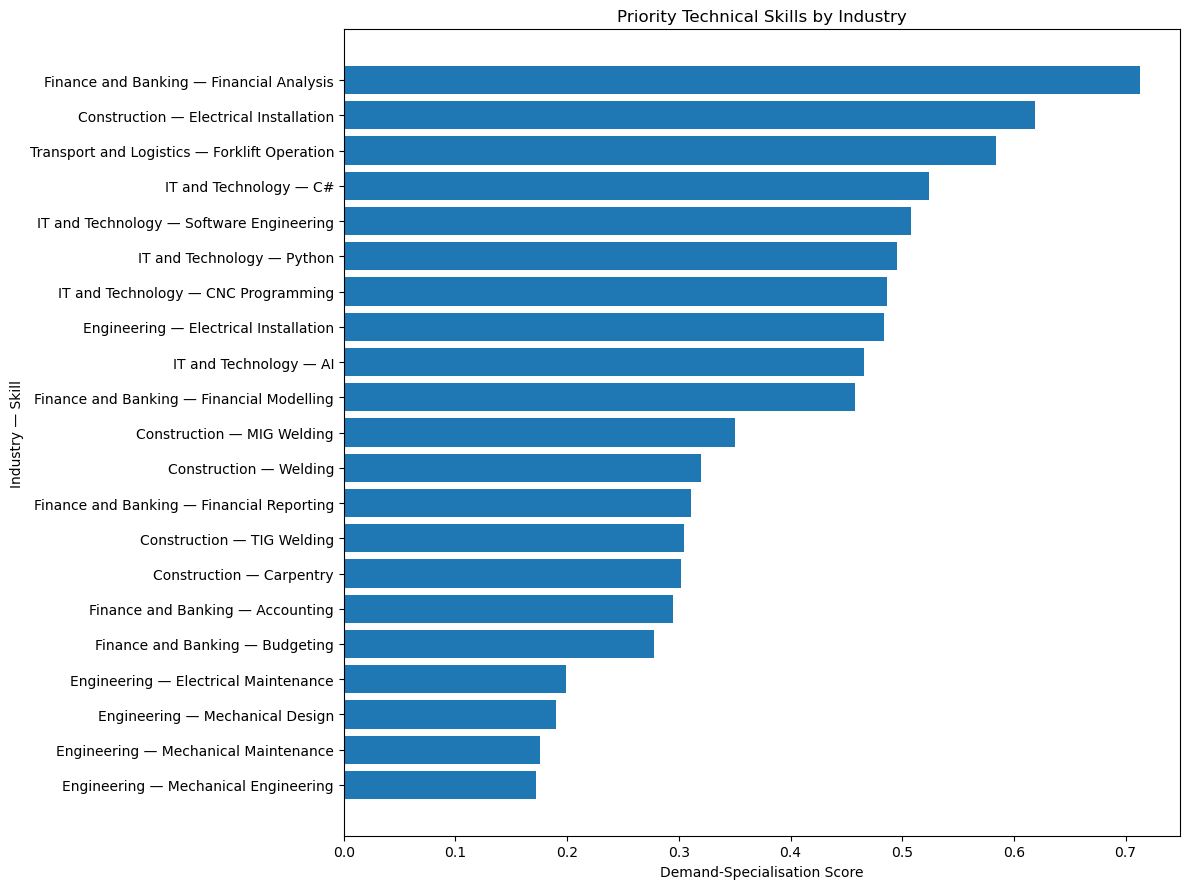

In [64]:
# ============================================================
# PRIORITY SKILLS BY INDUSTRY — VISUALISATION
# ============================================================

import matplotlib.pyplot as plt
import numpy as np

plot_df = priority_skill_table.copy()

# Create readable industry-skill labels
plot_df["industry_skill"] = (
    plot_df["industry"] + " — " + plot_df["skill"]
)

# Sort for horizontal bar chart
plot_df = plot_df.sort_values(
    "demand_specialisation_score",
    ascending=True
)

plt.figure(figsize=(12, 9))

plt.barh(
    plot_df["industry_skill"],
    plot_df["demand_specialisation_score"]
)

plt.xlabel("Demand-Specialisation Score")
plt.ylabel("Industry — Skill")
plt.title("Priority Technical Skills by Industry")

plt.tight_layout()
plt.show()

In [65]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 1
# OVERALL SOFT SKILL DEMAND
# ============================================================

def parse_soft_skill_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []


# Parse soft skills
df["soft_skills_analysis"] = df["soft_skills"].apply(
    parse_soft_skill_list
)


# Create one record per job-skill combination
soft_skill_records = []

for _, row in df.iterrows():

    job_id = row["job_id"]
    industry = row["industry"]

    for skill in row["soft_skills_analysis"]:

        if pd.isna(skill):
            continue

        skill = str(skill).strip()

        if skill:
            soft_skill_records.append({
                "job_id": job_id,
                "industry": industry,
                "skill": skill
            })


soft_skill_df = pd.DataFrame(soft_skill_records)


# Remove duplicate skill mentions within the same job
if not soft_skill_df.empty:
    soft_skill_df = soft_skill_df.drop_duplicates(
        subset=["job_id", "skill"]
    )


# Calculate overall soft-skill demand
soft_skill_demand = (
    soft_skill_df
    .groupby("skill")["job_id"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)


# Percentage of all job postings
soft_skill_demand["demand_percentage"] = (
    soft_skill_demand["job_count"]
    / len(df)
    * 100
)


# Summary
print("=" * 70)
print("OVERALL SOFT SKILL DEMAND")
print("=" * 70)

print(f"Jobs in dataset: {len(df):,}")
print(
    f"Jobs with soft skills: "
    f"{soft_skill_df['job_id'].nunique():,}"
)
print(
    f"Unique soft skills: "
    f"{soft_skill_demand['skill'].nunique():,}"
)

display(
    soft_skill_demand.head(20)
)

OVERALL SOFT SKILL DEMAND
Jobs in dataset: 19,207
Jobs with soft skills: 6,424
Unique soft skills: 1,531


,skill,job_count,demand_percentage
259,Communication,2352,12.245535
1054,Problem Solving,2184,11.370854
78,Attention to Detail,1944,10.121310
1418,Teamwork,1843,9.595460
776,Leadership,1449,7.544125
348,Customer Service,824,4.290103
1447,Time Management,396,2.061748
1045,Proactive,336,1.749362
1166,Reliable,170,0.885094
908,Organised,151,0.786172


In [66]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 2
# SOFT SKILL DEMAND BY INDUSTRY
# ============================================================

industry_soft_skill_demand = (
    soft_skill_df
    .groupby(["industry", "skill"])["job_id"]
    .nunique()
    .reset_index(name="job_count")
)


# Total number of jobs in each industry
industry_job_counts_soft = (
    df.groupby("industry")["job_id"]
    .nunique()
    .reset_index(name="industry_job_count")
)


# Merge industry totals
industry_soft_skill_demand = industry_soft_skill_demand.merge(
    industry_job_counts_soft,
    on="industry",
    how="left"
)


# Calculate percentage within each industry
industry_soft_skill_demand["demand_percentage"] = (
    industry_soft_skill_demand["job_count"]
    / industry_soft_skill_demand["industry_job_count"]
    * 100
)


# Sort by industry and demand
industry_soft_skill_demand = (
    industry_soft_skill_demand
    .sort_values(
        ["industry", "demand_percentage"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("SOFT SKILL DEMAND BY INDUSTRY")
print("=" * 70)

print(
    f"Industry-skill records: "
    f"{len(industry_soft_skill_demand):,}"
)

print(
    f"Industries represented: "
    f"{industry_soft_skill_demand['industry'].nunique():,}"
)


# Display top 10 soft skills for each industry
top_soft_skills_by_industry = (
    industry_soft_skill_demand
    .groupby("industry")
    .head(10)
    .copy()
)


display(
    top_soft_skills_by_industry[
        [
            "industry",
            "skill",
            "job_count",
            "industry_job_count",
            "demand_percentage"
        ]
    ]
)

SOFT SKILL DEMAND BY INDUSTRY
Industry-skill records: 2,316
Industries represented: 17


,industry,skill,job_count,industry_job_count,demand_percentage
0,Automotive,Customer Service,14,239,5.857741
1,Automotive,Flexibility,9,239,3.765690
2,Automotive,Communication,7,239,2.928870
3,Automotive,Problem Solving,7,239,2.928870
4,Automotive,Teamwork,6,239,2.510460
...,...,...,...,...,...
2230,Transport and Logistics,Customer Service,36,874,4.118993
2231,Transport and Logistics,Reliable,30,874,3.432494
2232,Transport and Logistics,Time Management,20,874,2.288330
2233,Transport and Logistics,Reliability,15,874,1.716247


In [67]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 3
# RELATIVE SOFT-SKILL DEMAND BY INDUSTRY
# ============================================================

# Overall soft-skill demand
overall_soft_skill_demand = (
    soft_skill_df
    .groupby("skill")["job_id"]
    .nunique()
    .reset_index(name="overall_job_count")
)

overall_soft_skill_demand["overall_demand_percentage"] = (
    overall_soft_skill_demand["overall_job_count"]
    / len(df)
    * 100
)


# Merge overall demand with industry-level demand
relative_soft_skill_demand = (
    industry_soft_skill_demand
    .merge(
        overall_soft_skill_demand,
        on="skill",
        how="left"
    )
)


# Calculate relative demand ratio
relative_soft_skill_demand["relative_demand_ratio"] = (
    relative_soft_skill_demand["demand_percentage"]
    / relative_soft_skill_demand["overall_demand_percentage"]
)


# Sort by relative demand
relative_soft_skill_demand = (
    relative_soft_skill_demand
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("RELATIVE SOFT-SKILL DEMAND BY INDUSTRY")
print("=" * 70)

print(
    f"Industry-skill records: "
    f"{len(relative_soft_skill_demand):,}"
)

print(
    f"Unique soft skills: "
    f"{relative_soft_skill_demand['skill'].nunique():,}"
)

print(
    f"Industries represented: "
    f"{relative_soft_skill_demand['industry'].nunique():,}"
)


display(
    relative_soft_skill_demand[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ].head(20)
)

RELATIVE SOFT-SKILL DEMAND BY INDUSTRY
Industry-skill records: 2,316
Unique soft skills: 1,531
Industries represented: 17


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
0,Real Estate,Check Diary Every Day,1,2.702703,0.005206,519.108108
1,Real Estate,Building Strong Tenant Relationships,1,2.702703,0.005206,519.108108
2,Real Estate,Property Visit,1,2.702703,0.005206,519.108108
3,Real Estate,Move In Check Out,1,2.702703,0.005206,519.108108
4,Real Estate,Staying Top of Compliance,1,2.702703,0.005206,519.108108
5,Real Estate,Organise Necessary,1,2.702703,0.005206,519.108108
6,Real Estate,Independently,1,2.702703,0.005206,519.108108
7,Real Estate,Strong Understanding,1,2.702703,0.005206,519.108108
8,Insurance,Natural resource underwriting,1,2.083333,0.005206,400.145833
9,Insurance,Strategic Development,1,2.083333,0.005206,400.145833


In [68]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 4
# LOW-FREQUENCY FILTER
# ============================================================

MIN_INDUSTRY_JOB_COUNT_SOFT = 5

soft_skill_gap_candidates = (
    relative_soft_skill_demand[
        relative_soft_skill_demand["job_count"]
        >= MIN_INDUSTRY_JOB_COUNT_SOFT
    ]
    .copy()
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("FILTERED SOFT-SKILL DEMAND CANDIDATES")
print("=" * 70)

print(
    f"Original industry-skill records: "
    f"{len(relative_soft_skill_demand):,}"
)

print(
    f"After minimum job-count threshold "
    f"(>= {MIN_INDUSTRY_JOB_COUNT_SOFT} jobs): "
    f"{len(soft_skill_gap_candidates):,}"
)

print(
    f"Industries represented: "
    f"{soft_skill_gap_candidates['industry'].nunique():,}"
)

print(
    f"Unique soft skills represented: "
    f"{soft_skill_gap_candidates['skill'].nunique():,}"
)


# Display highest relative-demand candidates
display(
    soft_skill_gap_candidates[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .head(20)
)

FILTERED SOFT-SKILL DEMAND CANDIDATES
Original industry-skill records: 2,316
After minimum job-count threshold (>= 5 jobs): 301
Industries represented: 17
Unique soft skills represented: 141


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
131,Healthcare,Companionship,5,2.173913,0.031239,69.590580
200,Healthcare,Compassion,12,5.217391,0.182225,28.631553
265,Education,Interest,6,0.601202,0.031239,19.245491
266,Education,Encouragement,26,2.605210,0.135367,19.245491
267,Education,Genuine interest in helping others succeed,9,0.901804,0.046858,19.245491
268,Education,Interest in helping students succeed,35,3.507014,0.182225,19.245491
269,Education,Genuine interest helping others succeed,14,1.402806,0.072890,19.245491
270,Education,Interest in Helping Students Succeed,12,1.202405,0.062477,19.245491
282,Education,Listening Skill,10,1.002004,0.052064,19.245491
355,Education,Listening,104,10.420842,0.551882,18.882369


In [69]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 5
# INDUSTRY SOFT-SKILL SPECIALISATION SCORE
# ============================================================

# Maximum values used for normalisation
soft_industry_max = (
    soft_skill_gap_candidates["demand_percentage"].max()
)

soft_relative_max = (
    soft_skill_gap_candidates["relative_demand_ratio"].max()
)

soft_count_max = (
    soft_skill_gap_candidates["job_count"].max()
)


# ------------------------------------------------------------
# Component 1 — Industry Demand Score
# ------------------------------------------------------------

soft_skill_gap_candidates["demand_score"] = (
    soft_skill_gap_candidates["demand_percentage"]
    / soft_industry_max
)


# ------------------------------------------------------------
# Component 2 — Specialisation Score
# ------------------------------------------------------------

soft_skill_gap_candidates["specialisation_score"] = (
    soft_skill_gap_candidates["relative_demand_ratio"]
    / soft_relative_max
)


# ------------------------------------------------------------
# Component 3 — Frequency Score
# ------------------------------------------------------------

soft_skill_gap_candidates["frequency_score"] = (
    soft_skill_gap_candidates["job_count"]
    / soft_count_max
)


# ------------------------------------------------------------
# Combined Industry Soft-Skill Score
# ------------------------------------------------------------

soft_skill_gap_candidates["industry_soft_skill_score"] = (
    0.40 * soft_skill_gap_candidates["demand_score"]
    + 0.35 * soft_skill_gap_candidates["specialisation_score"]
    + 0.25 * soft_skill_gap_candidates["frequency_score"]
)


# ------------------------------------------------------------
# Rank within each industry
# ------------------------------------------------------------

soft_skill_gap_candidates["industry_soft_skill_rank"] = (
    soft_skill_gap_candidates
    .groupby("industry")["industry_soft_skill_score"]
    .rank(
        method="dense",
        ascending=False
    )
)


# ------------------------------------------------------------
# Sort
# ------------------------------------------------------------

soft_skill_gap_candidates = (
    soft_skill_gap_candidates
    .sort_values(
        ["industry", "industry_soft_skill_score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("INDUSTRY SOFT-SKILL SPECIALISATION SCORE")
print("=" * 70)

print(
    f"Candidate records: "
    f"{len(soft_skill_gap_candidates):,}"
)

print(
    f"Industries represented: "
    f"{soft_skill_gap_candidates['industry'].nunique():,}"
)


display(
    soft_skill_gap_candidates[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_soft_skill_score",
            "industry_soft_skill_rank"
        ]
    ]
    .head(30)
)

INDUSTRY SOFT-SKILL SPECIALISATION SCORE
Candidate records: 301
Industries represented: 17


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_soft_skill_score,industry_soft_skill_rank
0,Automotive,Flexibility,9,3.765690,0.557089,6.759590,0.065443,1.0
1,Automotive,Customer Service,14,5.857741,4.290103,1.365408,0.055784,2.0
2,Automotive,Problem Solving,7,2.928870,11.370854,0.257577,0.025754,3.0
3,Automotive,Communication,7,2.928870,12.245535,0.239179,0.025661,4.0
4,Automotive,Teamwork,6,2.510460,9.595460,0.261630,0.022280,5.0
5,Automotive,Attention to Detail,5,2.092050,10.121310,0.206698,0.018510,6.0
6,Construction,Communication,43,3.662692,12.245535,0.299104,0.038907,1.0
7,Construction,Problem Solving,41,3.492334,11.370854,0.307130,0.037208,2.0
8,Construction,Attention to Detail,35,2.981261,10.121310,0.294553,0.031925,3.0
9,Construction,Teamwork,32,2.725724,9.595460,0.284064,0.029263,4.0


In [70]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 6
# HIGH-DEMAND INDUSTRY-SPECIALISED SOFT SKILLS
# ============================================================

MIN_SOFT_JOB_COUNT = 10
MIN_SOFT_DEMAND_PERCENTAGE = 1.0
MIN_SOFT_RELATIVE_RATIO = 2.0


high_demand_specialised_soft = (
    soft_skill_gap_candidates[
        (soft_skill_gap_candidates["job_count"] >= MIN_SOFT_JOB_COUNT)
        & (
            soft_skill_gap_candidates["demand_percentage"]
            >= MIN_SOFT_DEMAND_PERCENTAGE
        )
        & (
            soft_skill_gap_candidates["relative_demand_ratio"]
            >= MIN_SOFT_RELATIVE_RATIO
        )
    ]
    .copy()
)


# Sort by combined score
high_demand_specialised_soft = (
    high_demand_specialised_soft
    .sort_values(
        "industry_soft_skill_score",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("HIGH-DEMAND INDUSTRY-SPECIALISED SOFT SKILLS")
print("=" * 70)

print(
    f"Candidate records: "
    f"{len(high_demand_specialised_soft):,}"
)

print(
    f"Industries represented: "
    f"{high_demand_specialised_soft['industry'].nunique():,}"
)

print(
    f"Unique soft skills represented: "
    f"{high_demand_specialised_soft['skill'].nunique():,}"
)


display(
    high_demand_specialised_soft[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_soft_skill_score"
        ]
    ]
)

HIGH-DEMAND INDUSTRY-SPECIALISED SOFT SKILLS
Candidate records: 43
Industries represented: 9
Unique soft skills represented: 26


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_soft_skill_score
0,Retail,Customer Service,96,50.793651,4.290103,11.839729,0.478655
1,Education,Communication,366,36.673347,12.245535,2.994834,0.376715
2,Retail,Teamwork,62,32.804233,9.595460,3.418724,0.287868
3,Retail,Problem Solving,62,32.804233,11.370854,2.884940,0.285184
4,Human Resources,Communication,64,31.372549,12.245535,2.561958,0.272683
5,Retail,Communication,56,29.629630,12.245535,2.419627,0.256649
6,Real Estate,Problem Solving,11,29.729730,11.370854,2.614555,0.249461
7,Real Estate,Communication,11,29.729730,12.245535,2.427802,0.248522
8,Healthcare,Communication,65,28.260870,12.245535,2.307851,0.247099
9,Retail,Leadership,51,26.984127,7.544125,3.576840,0.240641


In [71]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 7
# SOFT-SKILL MARKET PRESSURE SCORE
# ============================================================

soft_skill_intelligence = high_demand_specialised_soft.copy()


# ------------------------------------------------------------
# Normalised demand component
# ------------------------------------------------------------

demand_max_soft = (
    soft_skill_intelligence["demand_percentage"].max()
)

soft_skill_intelligence["demand_component"] = (
    soft_skill_intelligence["demand_percentage"]
    / demand_max_soft
)


# ------------------------------------------------------------
# Normalised specialisation component
# ------------------------------------------------------------

specialisation_max_soft = (
    soft_skill_intelligence["relative_demand_ratio"].max()
)

soft_skill_intelligence["specialisation_component"] = (
    soft_skill_intelligence["relative_demand_ratio"]
    / specialisation_max_soft
)


# ------------------------------------------------------------
# Combined Market Pressure Score
# ------------------------------------------------------------

soft_skill_intelligence["soft_skill_market_pressure_score"] = (
    0.55 * soft_skill_intelligence["demand_component"]
    + 0.45 * soft_skill_intelligence["specialisation_component"]
)


# ------------------------------------------------------------
# Rank within each industry
# ------------------------------------------------------------

soft_skill_intelligence["soft_skill_rank"] = (
    soft_skill_intelligence
    .groupby("industry")[
        "soft_skill_market_pressure_score"
    ]
    .rank(
        method="dense",
        ascending=False
    )
)


# ------------------------------------------------------------
# Sort final results
# ------------------------------------------------------------

soft_skill_intelligence = (
    soft_skill_intelligence
    .sort_values(
        "soft_skill_market_pressure_score",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("SOFT-SKILL MARKET PRESSURE SCORE")
print("=" * 70)

print(
    f"Final candidate records: "
    f"{len(soft_skill_intelligence):,}"
)

print(
    f"Industries represented: "
    f"{soft_skill_intelligence['industry'].nunique():,}"
)

print(
    f"Unique soft skills represented: "
    f"{soft_skill_intelligence['skill'].nunique():,}"
)


display(
    soft_skill_intelligence[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "soft_skill_market_pressure_score",
            "soft_skill_rank"
        ]
    ]
)

SOFT-SKILL MARKET PRESSURE SCORE
Final candidate records: 43
Industries represented: 9
Unique soft skills represented: 26


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,soft_skill_market_pressure_score,soft_skill_rank
0,Retail,Customer Service,96,50.793651,4.290103,11.839729,0.736084,1.0
1,Healthcare,Compassion,12,5.217391,0.182225,28.631553,0.506495,1.0
2,Education,Communication,366,36.673347,12.245535,2.994834,0.444173,1.0
3,Education,Listening,104,10.420842,0.551882,18.882369,0.409611,2.0
4,Retail,Teamwork,62,32.804233,9.595460,3.418724,0.408940,2.0
5,Retail,Problem Solving,62,32.804233,11.370854,2.884940,0.400551,3.0
6,Human Resources,Communication,64,31.372549,12.245535,2.561958,0.379972,1.0
7,Real Estate,Problem Solving,11,29.729730,11.370854,2.614555,0.363010,1.0
8,Real Estate,Communication,11,29.729730,12.245535,2.427802,0.360075,2.0
9,Retail,Communication,56,29.629630,12.245535,2.419627,0.358862,4.0


In [72]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 8
# COMPACT PRIORITY SOFT-SKILL TABLE
# ============================================================

priority_soft_skills = (
    soft_skill_intelligence
    .sort_values(
        ["industry", "soft_skill_market_pressure_score"],
        ascending=[True, False]
    )
    .groupby("industry")
    .head(5)
    .copy()
)


# Rank within each industry
priority_soft_skills["industry_priority_rank"] = (
    priority_soft_skills
    .groupby("industry")[
        "soft_skill_market_pressure_score"
    ]
    .rank(
        method="dense",
        ascending=False
    )
)


# Final readable table
priority_soft_skill_table = (
    priority_soft_skills[
        [
            "industry",
            "skill",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "soft_skill_market_pressure_score",
            "industry_priority_rank"
        ]
    ]
    .sort_values(
        ["industry", "industry_priority_rank"]
    )
    .reset_index(drop=True)
)


# Round numerical values
priority_soft_skill_table[
    [
        "demand_percentage",
        "overall_demand_percentage",
        "relative_demand_ratio",
        "soft_skill_market_pressure_score"
    ]
] = priority_soft_skill_table[
    [
        "demand_percentage",
        "overall_demand_percentage",
        "relative_demand_ratio",
        "soft_skill_market_pressure_score"
    ]
].round(3)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("COMPACT PRIORITY SOFT-SKILL INTELLIGENCE TABLE")
print("=" * 70)

print(
    f"Priority soft-skill records: "
    f"{len(priority_soft_skill_table):,}"
)

print(
    f"Industries represented: "
    f"{priority_soft_skill_table['industry'].nunique():,}"
)

display(priority_soft_skill_table)

COMPACT PRIORITY SOFT-SKILL INTELLIGENCE TABLE
Priority soft-skill records: 32
Industries represented: 9


,industry,skill,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,soft_skill_market_pressure_score,industry_priority_rank
0,Education,Communication,366,36.673,12.246,2.995,0.444,1.0
1,Education,Listening,104,10.421,0.552,18.882,0.410,2.0
2,Education,Interest in helping students succeed,35,3.507,0.182,19.245,0.340,3.0
3,Education,Encouragement,26,2.605,0.135,19.245,0.331,4.0
4,Education,Genuine interest helping others succeed,14,1.403,0.073,19.245,0.318,5.0
5,Healthcare,Compassion,12,5.217,0.182,28.632,0.506,1.0
6,Healthcare,Communication,65,28.261,12.246,2.308,0.342,2.0
7,Healthcare,Teamwork,57,24.783,9.595,2.583,0.309,3.0
8,Healthcare,Compassionate,10,4.348,0.307,14.154,0.270,4.0
9,Healthcare,Customer Service,24,10.435,4.290,2.432,0.151,5.0


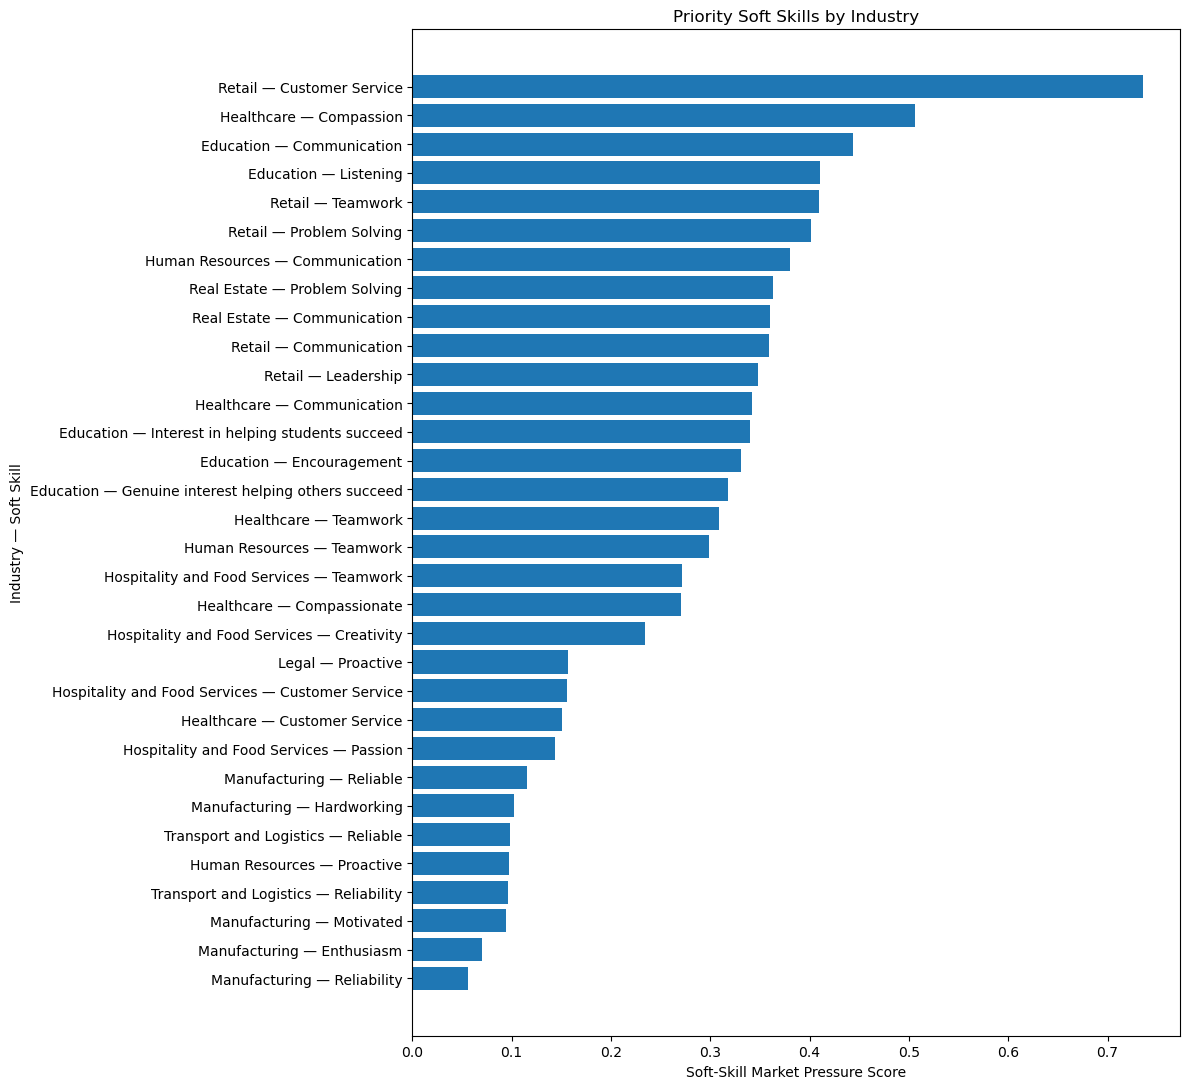

In [73]:
# ============================================================
# SOFT SKILL INTELLIGENCE — STEP 9
# PRIORITY SOFT SKILLS VISUALISATION
# ============================================================

plot_soft = priority_soft_skill_table.copy()

# Create readable labels
plot_soft["industry_skill"] = (
    plot_soft["industry"]
    + " — "
    + plot_soft["skill"]
)

# Sort for horizontal bar chart
plot_soft = plot_soft.sort_values(
    "soft_skill_market_pressure_score",
    ascending=True
)


plt.figure(figsize=(12, 11))

plt.barh(
    plot_soft["industry_skill"],
    plot_soft["soft_skill_market_pressure_score"]
)

plt.xlabel("Soft-Skill Market Pressure Score")
plt.ylabel("Industry — Soft Skill")
plt.title(
    "Priority Soft Skills by Industry"
)

plt.tight_layout()
plt.show()

In [74]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 1
# OVERALL TOOLS & TECHNOLOGIES DEMAND
# ============================================================

def parse_tools_list(value):
    if isinstance(value, list):
        return value

    if pd.isna(value):
        return []

    try:
        parsed = ast.literal_eval(str(value))
        return parsed if isinstance(parsed, list) else []
    except (ValueError, SyntaxError):
        return []


# Parse tools and technologies
df["tools_analysis"] = df["tools_and_technologies"].apply(
    parse_tools_list
)


# Create one record per job-tool combination
tools_records = []

for _, row in df.iterrows():

    job_id = row["job_id"]
    industry = row["industry"]

    for tool in row["tools_analysis"]:

        if pd.isna(tool):
            continue

        tool = str(tool).strip()

        if tool:
            tools_records.append({
                "job_id": job_id,
                "industry": industry,
                "tool": tool
            })


tools_df = pd.DataFrame(tools_records)


# Remove duplicate tool mentions within the same job
if not tools_df.empty:
    tools_df = tools_df.drop_duplicates(
        subset=["job_id", "tool"]
    )


# Calculate overall tool demand
tool_demand = (
    tools_df
    .groupby("tool")["job_id"]
    .nunique()
    .reset_index(name="job_count")
    .sort_values("job_count", ascending=False)
)


# Percentage of all job postings
tool_demand["demand_percentage"] = (
    tool_demand["job_count"]
    / len(df)
    * 100
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("OVERALL TOOLS & TECHNOLOGIES DEMAND")
print("=" * 70)

print(
    f"Jobs in dataset: "
    f"{len(df):,}"
)

print(
    f"Jobs with tools/technologies: "
    f"{tools_df['job_id'].nunique():,}"
)

print(
    f"Unique tools/technologies: "
    f"{tool_demand['tool'].nunique():,}"
)


display(
    tool_demand.head(20)
)

OVERALL TOOLS & TECHNOLOGIES DEMAND
Jobs in dataset: 19,207
Jobs with tools/technologies: 779
Unique tools/technologies: 643


,tool,job_count,demand_percentage
583,Uber Eats app,84,0.437341
369,Microsoft Excel,42,0.218670
494,SAP,29,0.150987
6,AWS,25,0.130161
48,Azure,17,0.088509
81,CAD,16,0.083303
213,Excel,16,0.083303
34,AutoCAD,15,0.078097
581,Uber Eats App,14,0.072890
370,Microsoft Fabric,12,0.062477


In [75]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 2
# DEMAND BY INDUSTRY
# ============================================================

industry_tool_demand = (
    tools_df
    .groupby(["industry", "tool"])["job_id"]
    .nunique()
    .reset_index(name="job_count")
)


# Total jobs in each industry
industry_job_counts_tools = (
    df.groupby("industry")["job_id"]
    .nunique()
    .reset_index(name="industry_job_count")
)


# Merge industry totals
industry_tool_demand = industry_tool_demand.merge(
    industry_job_counts_tools,
    on="industry",
    how="left"
)


# Calculate demand percentage within each industry
industry_tool_demand["demand_percentage"] = (
    industry_tool_demand["job_count"]
    / industry_tool_demand["industry_job_count"]
    * 100
)


# Sort by industry and demand
industry_tool_demand = (
    industry_tool_demand
    .sort_values(
        ["industry", "demand_percentage"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("TOOLS & TECHNOLOGIES DEMAND BY INDUSTRY")
print("=" * 70)

print(
    f"Industry-tool records: "
    f"{len(industry_tool_demand):,}"
)

print(
    f"Industries represented: "
    f"{industry_tool_demand['industry'].nunique():,}"
)

print(
    f"Unique tools/technologies: "
    f"{industry_tool_demand['tool'].nunique():,}"
)


# Top 10 tools for each industry
top_tools_by_industry = (
    industry_tool_demand
    .groupby("industry")
    .head(10)
    .copy()
)


display(
    top_tools_by_industry[
        [
            "industry",
            "tool",
            "job_count",
            "industry_job_count",
            "demand_percentage"
        ]
    ]
)

TOOLS & TECHNOLOGIES DEMAND BY INDUSTRY
Industry-tool records: 735
Industries represented: 16
Unique tools/technologies: 643


,industry,tool,job_count,industry_job_count,demand_percentage
0,Automotive,Autel,1,239,0.418410
1,Automotive,ISTA,1,239,0.418410
2,Automotive,Latest Facility,1,239,0.418410
3,Automotive,ODIS VCDs,1,239,0.418410
4,Construction,CNC Programming,1,1174,0.085179
...,...,...,...,...,...
710,Transport and Logistics,Bendi Flexi Forklift,1,874,0.114416
711,Transport and Logistics,Bendi flexi forklift truck,1,874,0.114416
712,Transport and Logistics,Bicycle,1,874,0.114416
713,Transport and Logistics,CNC machine,1,874,0.114416


In [76]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 3
# RELATIVE TOOL DEMAND BY INDUSTRY
# ============================================================

# Overall tool demand
overall_tool_demand = (
    tools_df
    .groupby("tool")["job_id"]
    .nunique()
    .reset_index(name="overall_job_count")
)

overall_tool_demand["overall_demand_percentage"] = (
    overall_tool_demand["overall_job_count"]
    / len(df)
    * 100
)


# Merge overall demand with industry-level demand
relative_tool_demand = (
    industry_tool_demand
    .merge(
        overall_tool_demand,
        on="tool",
        how="left"
    )
)


# Calculate relative demand ratio
relative_tool_demand["relative_demand_ratio"] = (
    relative_tool_demand["demand_percentage"]
    / relative_tool_demand["overall_demand_percentage"]
)


# Sort by relative demand
relative_tool_demand = (
    relative_tool_demand
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("RELATIVE TOOLS & TECHNOLOGIES DEMAND BY INDUSTRY")
print("=" * 70)

print(
    f"Industry-tool records: "
    f"{len(relative_tool_demand):,}"
)

print(
    f"Unique tools/technologies: "
    f"{relative_tool_demand['tool'].nunique():,}"
)

print(
    f"Industries represented: "
    f"{relative_tool_demand['industry'].nunique():,}"
)


display(
    relative_tool_demand[
        [
            "industry",
            "tool",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ].head(20)
)

RELATIVE TOOLS & TECHNOLOGIES DEMAND BY INDUSTRY
Industry-tool records: 735
Unique tools/technologies: 643
Industries represented: 16


,industry,tool,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
0,Insurance,Model based rating bench,1,2.083333,0.005206,400.145833
1,Marketing and Advertising,Article,1,0.729927,0.005206,140.197080
2,Marketing and Advertising,Hubspot,1,0.729927,0.005206,140.197080
3,Marketing and Advertising,Social Post,1,0.729927,0.005206,140.197080
4,Marketing and Advertising,Video,1,0.729927,0.005206,140.197080
5,Retail,Point of Sale (POS),1,0.529101,0.005206,101.624339
6,Human Resources,People System,1,0.490196,0.005206,94.151961
7,Human Resources,Tech Savvy,1,0.490196,0.005206,94.151961
8,Human Resources,Personnel File,1,0.490196,0.005206,94.151961
9,Human Resources,Learning management,1,0.490196,0.005206,94.151961


In [77]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 4
# LOW-FREQUENCY FILTER
# ============================================================

MIN_INDUSTRY_JOB_COUNT_TOOLS = 5

tool_gap_candidates = (
    relative_tool_demand[
        relative_tool_demand["job_count"]
        >= MIN_INDUSTRY_JOB_COUNT_TOOLS
    ]
    .copy()
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("FILTERED TOOLS & TECHNOLOGIES DEMAND CANDIDATES")
print("=" * 70)

print(
    f"Original industry-tool records: "
    f"{len(relative_tool_demand):,}"
)

print(
    f"After minimum job-count threshold "
    f"(>= {MIN_INDUSTRY_JOB_COUNT_TOOLS} jobs): "
    f"{len(tool_gap_candidates):,}"
)

print(
    f"Industries represented: "
    f"{tool_gap_candidates['industry'].nunique():,}"
)

print(
    f"Unique tools/technologies represented: "
    f"{tool_gap_candidates['tool'].nunique():,}"
)


# Display highest relative-demand candidates
display(
    tool_gap_candidates[
        [
            "industry",
            "tool",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio"
        ]
    ]
    .sort_values(
        "relative_demand_ratio",
        ascending=False
    )
    .head(30)
)

FILTERED TOOLS & TECHNOLOGIES DEMAND CANDIDATES
Original industry-tool records: 735
After minimum job-count threshold (>= 5 jobs): 28
Industries represented: 6
Unique tools/technologies represented: 21


,industry,tool,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio
127,IT and Technology,Fanuc,5,0.819672,0.041651,19.679303
166,Transport and Logistics,Forklift,7,0.800915,0.046858,17.092423
220,Transport and Logistics,Forklift Operation,6,0.686499,0.046858,14.650648
221,IT and Technology,AWS,10,1.639344,0.130161,12.594754
222,IT and Technology,Azure,6,0.983607,0.088509,11.113018
241,Finance and Banking,Excel,7,0.657895,0.083303,7.897615
248,Engineering,Tool Technology,7,0.273331,0.036445,7.499805
341,Finance and Banking,Microsoft Excel,15,1.409774,0.218670,6.447033
344,Engineering,Solidworks,5,0.195236,0.031239,6.249837
366,Engineering,AutoCAD,7,0.273331,0.078097,3.499909


In [78]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 5
# INDUSTRY TOOL SPECIALISATION SCORE
# ============================================================

tool_industry_max = (
    tool_gap_candidates["demand_percentage"].max()
)

tool_relative_max = (
    tool_gap_candidates["relative_demand_ratio"].max()
)

tool_count_max = (
    tool_gap_candidates["job_count"].max()
)


# ------------------------------------------------------------
# Component 1 — Industry Demand Score
# ------------------------------------------------------------

tool_gap_candidates["demand_score"] = (
    tool_gap_candidates["demand_percentage"]
    / tool_industry_max
)


# ------------------------------------------------------------
# Component 2 — Specialisation Score
# ------------------------------------------------------------

tool_gap_candidates["specialisation_score"] = (
    tool_gap_candidates["relative_demand_ratio"]
    / tool_relative_max
)


# ------------------------------------------------------------
# Component 3 — Frequency Score
# ------------------------------------------------------------

tool_gap_candidates["frequency_score"] = (
    tool_gap_candidates["job_count"]
    / tool_count_max
)


# ------------------------------------------------------------
# Combined Industry Tool Score
# ------------------------------------------------------------

tool_gap_candidates["industry_tool_score"] = (
    0.40 * tool_gap_candidates["demand_score"]
    + 0.35 * tool_gap_candidates["specialisation_score"]
    + 0.25 * tool_gap_candidates["frequency_score"]
)


# ------------------------------------------------------------
# Rank within each industry
# ------------------------------------------------------------

tool_gap_candidates["industry_tool_rank"] = (
    tool_gap_candidates
    .groupby("industry")["industry_tool_score"]
    .rank(
        method="dense",
        ascending=False
    )
)


# ------------------------------------------------------------
# Sort results
# ------------------------------------------------------------

tool_gap_candidates = (
    tool_gap_candidates
    .sort_values(
        ["industry", "industry_tool_score"],
        ascending=[True, False]
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("INDUSTRY TOOL SPECIALISATION SCORE")
print("=" * 70)

print(
    f"Candidate records: "
    f"{len(tool_gap_candidates):,}"
)

print(
    f"Industries represented: "
    f"{tool_gap_candidates['industry'].nunique():,}"
)

print(
    f"Unique tools/technologies: "
    f"{tool_gap_candidates['tool'].nunique():,}"
)


display(
    tool_gap_candidates[
        [
            "industry",
            "tool",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_tool_score",
            "industry_tool_rank"
        ]
    ]
)

INDUSTRY TOOL SPECIALISATION SCORE
Candidate records: 28
Industries represented: 6
Unique tools/technologies: 21


,industry,tool,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_tool_score,industry_tool_rank
0,Engineering,Tool Technology,7,0.273331,0.036445,7.499805,0.220911,1.0
1,Engineering,Solidworks,5,0.195236,0.031239,6.249837,0.173673,2.0
2,Engineering,AutoCAD,7,0.273331,0.078097,3.499909,0.149773,3.0
3,Finance and Banking,Microsoft Excel,15,1.409774,0.218670,6.447033,0.503289,1.0
4,Finance and Banking,Excel,7,0.657895,0.083303,7.897615,0.321820,2.0
5,Finance and Banking,SAP,5,0.469925,0.150987,3.112361,0.184897,3.0
6,IT and Technology,AWS,10,1.639344,0.130161,12.594754,0.653762,1.0
7,IT and Technology,Fanuc,5,0.819672,0.041651,19.679303,0.564881,2.0
8,IT and Technology,Azure,6,0.983607,0.088509,11.113018,0.455504,3.0
9,Manufacturing,SAP,5,0.420875,0.150987,2.787501,0.167151,1.0


In [79]:
# ============================================================
# TOOLS & TECHNOLOGIES INTELLIGENCE — STEP 6
# HIGH-DEMAND INDUSTRY-SPECIALISED TOOLS
# ============================================================

MIN_TOOL_JOB_COUNT = 5
MIN_TOOL_DEMAND_PERCENTAGE = 0.5
MIN_TOOL_RELATIVE_RATIO = 2.0


high_demand_specialised_tools = (
    tool_gap_candidates[
        (tool_gap_candidates["job_count"] >= MIN_TOOL_JOB_COUNT)
        & (
            tool_gap_candidates["demand_percentage"]
            >= MIN_TOOL_DEMAND_PERCENTAGE
        )
        & (
            tool_gap_candidates["relative_demand_ratio"]
            >= MIN_TOOL_RELATIVE_RATIO
        )
    ]
    .copy()
)


# Sort by industry tool score
high_demand_specialised_tools = (
    high_demand_specialised_tools
    .sort_values(
        "industry_tool_score",
        ascending=False
    )
    .reset_index(drop=True)
)


# ============================================================
# SUMMARY
# ============================================================

print("=" * 70)
print("HIGH-DEMAND INDUSTRY-SPECIALISED TOOLS")
print("=" * 70)

print(
    f"Candidate records: "
    f"{len(high_demand_specialised_tools):,}"
)

print(
    f"Industries represented: "
    f"{high_demand_specialised_tools['industry'].nunique():,}"
)

print(
    f"Unique tools/technologies represented: "
    f"{high_demand_specialised_tools['tool'].nunique():,}"
)


display(
    high_demand_specialised_tools[
        [
            "industry",
            "tool",
            "job_count",
            "demand_percentage",
            "overall_demand_percentage",
            "relative_demand_ratio",
            "industry_tool_score"
        ]
    ]
)

HIGH-DEMAND INDUSTRY-SPECIALISED TOOLS
Candidate records: 8
Industries represented: 4
Unique tools/technologies represented: 8


,industry,tool,job_count,demand_percentage,overall_demand_percentage,relative_demand_ratio,industry_tool_score
0,IT and Technology,AWS,10,1.639344,0.130161,12.594754,0.653762
1,IT and Technology,Fanuc,5,0.819672,0.041651,19.679303,0.564881
2,Transport and Logistics,Forklift,7,0.800915,0.046858,17.092423,0.520249
3,Other,Uber Eats app,84,0.921962,0.437341,2.108111,0.512452
4,Finance and Banking,Microsoft Excel,15,1.409774,0.218670,6.447033,0.503289
5,IT and Technology,Azure,6,0.983607,0.088509,11.113018,0.455504
6,Transport and Logistics,Forklift Operation,6,0.686499,0.046858,14.650648,0.445927
7,Finance and Banking,Excel,7,0.657895,0.083303,7.897615,0.321820


In [80]:
# ============================================
# OTHER INDUSTRY DIAGNOSTIC
# ============================================

other_df = df[df["industry"] == "Other"].copy()

print("Other jobs:", len(other_df))
print("Percentage of dataset:", round(len(other_df) / len(df) * 100, 2), "%")

print("\nTop 30 job titles in Other:")
display(
    other_df["title"]
    .value_counts()
    .head(30)
    .to_frame("job_count")
)

print("\nSample of Other job titles:")
display(
    other_df[["job_id", "title"]]
    .sample(min(30, len(other_df)), random_state=42)
)

Other jobs: 9111
Percentage of dataset: 47.44 %

Top 30 job titles in Other:


,job_count
title,
Looking For Part-Time Opportunities? - Deliver with Uber Eats,188
Deliver with Uber Eats - Sign Up and Start Earning,187
Be Your Own Boss - Deliver with Uber Eats,174
Delivery Opportunities Near Me? - Deliver with Uber Eats,166
Sign Up as A Delivery Person - Earn With Uber Eats,161
Business Development Manager,98
Project Manager,52
Buyer,40
Production Planner,36



Sample of Other job titles:


,job_id,title
5793,284fda6c-fc2c-43b6-a212-fdcd965a53c0,Director of Business Systems
6024,a9d18629-214a-4f0a-a89d-60aa34b4a801,Mobile Security Patrol Officer
6507,e0c958c3-b004-4dd9-8ad0-9d565fc73d69,Artisan Baker - 3AM start
16920,1a92e034-cc88-470f-851b-e11efcde3164,Deliver with Uber Eats - Sign Up and Start Ear...
8115,0ab9d1a5-96be-4125-8598-73446c51f2e3,Financial Planning & Analysis Manager
6624,967579c4-ce32-40e2-857f-df94295afc2e,Female Support Worker
5616,ccfd26f5-ab36-4990-8bdf-f4a4975af5f3,Commercial Operations Analyst
5352,fce7b7f3-91ed-43fc-b8a2-66437f4c4078,FX OpsTech Application Support - Assistant Vic...
11655,035384d7-ea30-4d42-9b57-e207a6661ecf,Customs & International Trade Regulations Analyst
16690,435b803f-c1c6-4e31-bccf-6e5a8a3f332c,Sign Up as A Delivery Person - Earn With Uber ...


In [81]:
# ============================================
# OTHER INDUSTRY - SKILL DIAGNOSTIC
# ============================================

print("TOP TECHNICAL SKILLS IN OTHER")
print("=" * 50)

other_technical = (
    other_df["technical_skills_parsed"]
    .explode()
    .dropna()
    .astype(str)
    .str.strip()
)

display(
    other_technical.value_counts()
    .head(30)
    .to_frame("job_count")
)


print("\nTOP SOFT SKILLS IN OTHER")
print("=" * 50)

other_soft = (
    other_df["soft_skills_parsed"]
    .explode()
    .dropna()
    .astype(str)
    .str.strip()
)

display(
    other_soft.value_counts()
    .head(30)
    .to_frame("job_count")
)


print("\nTOP TOOLS & TECHNOLOGIES IN OTHER")
print("=" * 50)

other_tools = (
    other_df["tools_and_technologies_parsed"]
    .explode()
    .dropna()
    .astype(str)
    .str.strip()
)

display(
    other_tools.value_counts()
    .head(30)
    .to_frame("job_count")
)

TOP TECHNICAL SKILLS IN OTHER


,job_count
technical_skills_parsed,
Electrical Installation,113
CNC Milling,50
CNC Machining,45
CAD,32
CNC Turning,25
Mechanical Fitting,18
Forklift Operation,17
Data Engineering,17
Data Analysis,16



TOP SOFT SKILLS IN OTHER


,job_count
soft_skills_parsed,
Communication,1256
Problem Solving,1146
Attention to Detail,1040
Teamwork,1008
Leadership,792
Customer Service,500
Time Management,236
Proactive,207
Organised,120



TOP TOOLS & TECHNOLOGIES IN OTHER


,job_count
tools_and_technologies_parsed,
Uber Eats app,84
Microsoft Excel,20
Uber Eats App,14
CAD,12
SAP,12
AWS,11
Tablet,11
Microsoft Fabric,10
AutoCAD,8


In [82]:
# ============================================
# SECOND-STAGE OTHER INDUSTRY CLASSIFICATION
# DATA PREPARATION
# ============================================

# Work on a copy so the original df is not modified
df_industry_refinement = df.copy()

# Separate already-classified jobs and Other jobs
classified_df = df_industry_refinement[
    df_industry_refinement["industry"] != "Other"
].copy()

other_jobs_df = df_industry_refinement[
    df_industry_refinement["industry"] == "Other"
].copy()

print("Already classified jobs:", len(classified_df))
print("Other jobs:", len(other_jobs_df))

print("\nExisting industry distribution:")
display(
    classified_df["industry"]
    .value_counts()
    .to_frame("job_count")
)

print("\nOther jobs available for second-stage classification:",
      len(other_jobs_df))

Already classified jobs: 10096
Other jobs: 9111

Existing industry distribution:


,job_count
industry,
Engineering,2561
Manufacturing,1188
Construction,1174
Finance and Banking,1064
Education,998
Transport and Logistics,874
IT and Technology,610
Hospitality and Food Services,316
Automotive,239



Other jobs available for second-stage classification: 9111


In [83]:
# ============================================
# CREATE SECOND-STAGE CLASSIFIER FEATURES
# ============================================

def list_to_text(value):
    """Convert parsed list values into searchable text."""
    if isinstance(value, list):
        return " ".join(str(x) for x in value)

    if pd.isna(value):
        return ""

    return str(value)


# Convert skill/tool lists into text
for col in [
    "technical_skills_parsed",
    "soft_skills_parsed",
    "tools_and_technologies_parsed"
]:
    if col in classified_df.columns:
        classified_df[col + "_text"] = (
            classified_df[col].apply(list_to_text)
        )

        other_jobs_df[col + "_text"] = (
            other_jobs_df[col].apply(list_to_text)
        )


# Build the final classifier text
def create_classifier_text(row):
    parts = [
        str(row.get("title", "")),
        str(row.get("description_clean", "")),
        str(row.get("technical_skills_parsed_text", "")),
        str(row.get("tools_and_technologies_parsed_text", ""))
    ]

    return " ".join(
        part for part in parts
        if part and part.lower() != "nan"
    )


classified_df["classifier_text"] = classified_df.apply(
    create_classifier_text,
    axis=1
)

other_jobs_df["classifier_text"] = other_jobs_df.apply(
    create_classifier_text,
    axis=1
)


print("Training records:", len(classified_df))
print("Other records:", len(other_jobs_df))

print("\nTraining text examples:")
display(
    classified_df[["industry", "title", "classifier_text"]]
    .head(3)
)

Training records: 10096
Other records: 9111

Training text examples:


,industry,title,classifier_text
0,Healthcare,Dispenser NVQ,Dispenser NVQ join superdrug pharmacy team whe...
1,Retail,Service Colleague Express,Service Colleague Express job title service co...
2,Retail,Service Colleague Express,Service Colleague Express job title service co...


In [84]:
# ============================================
# TRAIN SECOND-STAGE INDUSTRY CLASSIFIER
# TF-IDF + LOGISTIC REGRESSION
# ============================================

from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score


# Training features and labels
X = classified_df["classifier_text"]
y = classified_df["industry"]


# Split labelled data into training and validation sets
X_train, X_val, y_train, y_val = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)


print("Training samples:", len(X_train))
print("Validation samples:", len(X_val))


# TF-IDF representation
tfidf_other = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_df=0.95,
    sublinear_tf=True
)


X_train_tfidf = tfidf_other.fit_transform(X_train)
X_val_tfidf = tfidf_other.transform(X_val)


print("\nTF-IDF training matrix:", X_train_tfidf.shape)
print("TF-IDF validation matrix:", X_val_tfidf.shape)


# Logistic Regression classifier
industry_classifier_other = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)


industry_classifier_other.fit(
    X_train_tfidf,
    y_train
)


# Validation predictions
y_pred = industry_classifier_other.predict(X_val_tfidf)


# Evaluation
accuracy = accuracy_score(y_val, y_pred)

print("\nValidation Accuracy:", round(accuracy, 4))

print("\nClassification Report:")
print(
    classification_report(
        y_val,
        y_pred,
        zero_division=0
    )
)

Training samples: 8076
Validation samples: 2020

TF-IDF training matrix: (8076, 45222)
TF-IDF validation matrix: (2020, 45222)

Validation Accuracy: 0.947

Classification Report:
                               precision    recall  f1-score   support

                   Automotive       1.00      0.98      0.99        48
                 Construction       0.98      0.93      0.96       235
                    Education       0.99      0.97      0.98       200
                  Engineering       0.96      0.94      0.95       512
          Finance and Banking       0.98      0.97      0.97       213
                   Healthcare       0.88      0.93      0.91        46
Hospitality and Food Services       0.93      0.89      0.91        63
              Human Resources       0.95      0.98      0.96        41
            IT and Technology       0.83      0.95      0.89       122
                    Insurance       0.82      0.90      0.86        10
                        Legal       0.9

In [85]:
# ============================================
# APPLY SECOND-STAGE CLASSIFIER TO OTHER JOBS
# WITH CONFIDENCE SCORES
# ============================================

# Transform Other jobs using the already fitted TF-IDF vectorizer
X_other_tfidf = tfidf_other.transform(
    other_jobs_df["classifier_text"]
)

# Predict industry
other_predictions = industry_classifier_other.predict(
    X_other_tfidf
)

# Get prediction probabilities
other_probabilities = industry_classifier_other.predict_proba(
    X_other_tfidf
)

# Highest probability for each job
other_confidence = other_probabilities.max(axis=1)

# Create prediction dataframe
other_predictions_df = other_jobs_df[
    ["job_id", "title", "industry"]
].copy()

other_predictions_df["predicted_industry"] = other_predictions
other_predictions_df["prediction_confidence"] = other_confidence

# Sort by confidence
other_predictions_df = other_predictions_df.sort_values(
    "prediction_confidence",
    ascending=False
)

print("Total Other jobs:", len(other_predictions_df))

print("\nPrediction distribution:")
display(
    other_predictions_df["predicted_industry"]
    .value_counts()
    .to_frame("predicted_job_count")
)

print("\nConfidence statistics:")
display(
    other_predictions_df["prediction_confidence"]
    .describe()
)

print("\nHighest-confidence predictions:")
display(
    other_predictions_df[
        [
            "job_id",
            "title",
            "predicted_industry",
            "prediction_confidence"
        ]
    ].head(30)
)

Total Other jobs: 9111

Prediction distribution:


,predicted_job_count
predicted_industry,
Manufacturing,2037
Transport and Logistics,1682
Engineering,1325
Finance and Banking,1108
IT and Technology,731
Healthcare,474
Construction,433
Retail,303
Human Resources,233



Confidence statistics:


count    9111.000000
mean        0.280051
std         0.175346
min         0.083809
25%         0.161020
50%         0.218241
75%         0.346386
max         0.929851
Name: prediction_confidence, dtype: float64


Highest-confidence predictions:


,job_id,title,predicted_industry,prediction_confidence
18676,7a8ea996-7052-4221-896e-6004d7277750,Decorator (Self-Employed),Construction,0.929851
18679,3600e650-a32b-4f17-9740-10ee9ebda56b,Decorator (Self-Employed),Construction,0.929851
18678,da909a79-76ba-4121-8c9e-2459d11678dd,Decorator (Self-Employed),Construction,0.929851
18698,3a3154c5-fd8d-419c-a242-11dafea7efc3,Decorator (Self-Employed),Construction,0.929851
18697,b5d88d62-4b3c-4ea0-9f89-c6fe8f1d8f59,Decorator (Self-Employed),Construction,0.929851
18696,4e16df18-836e-4fd8-b643-6797334b21d7,Decorator (Self-Employed),Construction,0.929851
18695,d8f3e041-1944-426b-bd17-1ac679c56155,Decorator (Self-Employed),Construction,0.929851
18694,7e83b207-aa85-4d71-9daa-7f8c5da08ae0,Decorator (Self-Employed),Construction,0.929851
18693,c1da3f2c-27e2-4959-a23b-8d8f9068abc3,Decorator (Self-Employed),Construction,0.929851
18692,fdbb29be-c448-40ad-8e92-3fc5dde399d3,Decorator (Self-Employed),Construction,0.929851


In [86]:
# ============================================
# CONFIDENCE THRESHOLD ANALYSIS
# ============================================

import numpy as np
import pandas as pd

# Get validation probabilities
val_probabilities = industry_classifier_other.predict_proba(
    X_val_tfidf
)

# Maximum probability for each validation prediction
val_confidence = val_probabilities.max(axis=1)

# Predicted class
val_predictions = industry_classifier_other.predict(
    X_val_tfidf
)

# Whether prediction was correct
val_correct = (
    val_predictions == y_val.to_numpy()
)


thresholds = [0.50, 0.60, 0.70, 0.80, 0.90]

threshold_results = []

for threshold in thresholds:

    accepted = val_confidence >= threshold

    accepted_count = accepted.sum()

    if accepted_count > 0:
        accepted_accuracy = val_correct[accepted].mean()
    else:
        accepted_accuracy = np.nan

    coverage = accepted_count / len(val_confidence)

    threshold_results.append({
        "confidence_threshold": threshold,
        "accepted_jobs": accepted_count,
        "rejected_jobs": len(val_confidence) - accepted_count,
        "coverage": coverage,
        "accuracy_among_accepted": accepted_accuracy
    })


threshold_results_df = pd.DataFrame(threshold_results)

threshold_results_df["coverage"] = (
    threshold_results_df["coverage"] * 100
)

threshold_results_df["accuracy_among_accepted"] = (
    threshold_results_df["accuracy_among_accepted"] * 100
)


display(threshold_results_df.round(2))

,confidence_threshold,accepted_jobs,rejected_jobs,coverage,accuracy_among_accepted
0,0.5,1452,568,71.88,98.97
1,0.6,1234,786,61.09,99.51
2,0.7,989,1031,48.96,99.80
3,0.8,723,1297,35.79,99.72
4,0.9,428,1592,21.19,99.77


In [87]:
# ============================================
# APPLY CONFIDENCE THRESHOLD TO OTHER JOBS
# ============================================

CONFIDENCE_THRESHOLD = 0.60

# Start with the existing industry classification
other_jobs_refined = other_predictions_df.copy()

# Apply the confidence threshold
other_jobs_refined["refined_industry"] = np.where(
    other_jobs_refined["prediction_confidence"] >= CONFIDENCE_THRESHOLD,
    other_jobs_refined["predicted_industry"],
    "Other"
)

# Count how many jobs were successfully reassigned
reassigned_count = (
    other_jobs_refined["refined_industry"] != "Other"
).sum()

remaining_other_count = (
    other_jobs_refined["refined_industry"] == "Other"
).sum()

print("Confidence threshold:", CONFIDENCE_THRESHOLD)

print("\nJobs reassigned:", reassigned_count)
print("Jobs remaining Other:", remaining_other_count)

print(
    "Percentage of Other jobs reassigned:",
    round(reassigned_count / len(other_jobs_refined) * 100, 2),
    "%"
)

print(
    "Percentage of Other jobs remaining:",
    round(remaining_other_count / len(other_jobs_refined) * 100, 2),
    "%"
)

print("\nRefined industry distribution within original Other:")
display(
    other_jobs_refined["refined_industry"]
    .value_counts()
    .to_frame("job_count")
)

Confidence threshold: 0.6

Jobs reassigned: 615
Jobs remaining Other: 8496
Percentage of Other jobs reassigned: 6.75 %
Percentage of Other jobs remaining: 93.25 %

Refined industry distribution within original Other:


,job_count
refined_industry,
Other,8496
Construction,195
Manufacturing,89
Transport and Logistics,74
Finance and Banking,53
IT and Technology,34
Healthcare,33
Human Resources,28
Engineering,22


In [88]:
# ============================================
# QUALITY CHECK OF REASSIGNED JOBS
# ============================================

reassigned_jobs = other_jobs_refined[
    other_jobs_refined["refined_industry"] != "Other"
].copy()

print("Total reassigned jobs:", len(reassigned_jobs))

print("\nReassigned jobs by industry:")
display(
    reassigned_jobs["refined_industry"]
    .value_counts()
    .to_frame("job_count")
)

print("\nSample of reassigned jobs:")

display(
    reassigned_jobs[
        [
            "job_id",
            "title",
            "predicted_industry",
            "prediction_confidence"
        ]
    ]
    .sort_values(
        "prediction_confidence",
        ascending=False
    )
    .head(100)
)

Total reassigned jobs: 615

Reassigned jobs by industry:


,job_count
refined_industry,
Construction,195
Manufacturing,89
Transport and Logistics,74
Finance and Banking,53
IT and Technology,34
Healthcare,33
Human Resources,28
Engineering,22
Automotive,16



Sample of reassigned jobs:


,job_id,title,predicted_industry,prediction_confidence
18676,7a8ea996-7052-4221-896e-6004d7277750,Decorator (Self-Employed),Construction,0.929851
18689,e7ad7ac7-d94e-4c4a-ae6f-84b1e516bbf0,Decorator (Self-Employed),Construction,0.929851
18679,3600e650-a32b-4f17-9740-10ee9ebda56b,Decorator (Self-Employed),Construction,0.929851
18680,324a0942-40c0-4c78-a500-f8851dc1ee4a,Decorator (Self-Employed),Construction,0.929851
18677,d17d3cdd-7aca-4c38-b677-a5ae22caffd8,Decorator (Self-Employed),Construction,0.929851
...,...,...,...,...
18702,af3403fa-b882-4ce5-a295-b5612f4ca5f1,Floor Fitter (Self-Employed),Construction,0.919354
18727,be040676-682b-4a13-974b-23de31866fdd,Floor Fitter (Self-Employed),Construction,0.919354
18721,cdf0f161-bc60-4fac-96dd-924ec2ce7a0f,Floor Fitter (Self-Employed),Construction,0.919354
18722,45fa8f4d-5e51-4037-8c91-a80b0b26edec,Floor Fitter (Self-Employed),Construction,0.919354


In [89]:
# ============================================
# REASSIGNED JOB QUALITY SUMMARY
# ============================================

# Summary statistics for reassigned jobs
reassigned_summary = (
    reassigned_jobs
    .groupby("refined_industry")
    .agg(
        job_count=("job_id", "count"),
        average_confidence=("prediction_confidence", "mean"),
        minimum_confidence=("prediction_confidence", "min"),
        maximum_confidence=("prediction_confidence", "max")
    )
    .sort_values("job_count", ascending=False)
)

print("Reassigned job quality summary:")
display(
    reassigned_summary.round(3)
)

Reassigned job quality summary:


,job_count,average_confidence,minimum_confidence,maximum_confidence
refined_industry,,,,
Construction,195,0.918,0.890,0.930
Manufacturing,89,0.659,0.603,0.793
Transport and Logistics,74,0.709,0.601,0.915
Finance and Banking,53,0.682,0.601,0.851
IT and Technology,34,0.681,0.607,0.818
Healthcare,33,0.656,0.604,0.742
Human Resources,28,0.723,0.627,0.829
Engineering,22,0.660,0.602,0.750
Automotive,16,0.715,0.604,0.784


In [90]:
# ============================================
# INTEGRATE SECOND-STAGE INDUSTRY REFINEMENT
# ============================================

# Create a completely separate copy
df_refined = df.copy()

# Keep the original industry classification
df_refined["industry_original"] = df_refined["industry"]

# Create refined industry initially equal to original industry
df_refined["industry_refined"] = df_refined["industry"]

# Create mapping from job_id to refined industry
refined_industry_map = (
    reassigned_jobs
    .set_index("job_id")["refined_industry"]
    .to_dict()
)

# Apply the 615 high-confidence reassigned classifications
df_refined["industry_refined"] = (
    df_refined["job_id"]
    .map(refined_industry_map)
    .fillna(df_refined["industry_refined"])
)

# Validate row count
print("Original rows:", len(df))
print("Refined rows:", len(df_refined))

# Count changes
industry_changes = (
    df_refined["industry_original"]
    != df_refined["industry_refined"]
)

print("\nIndustry classifications changed:", industry_changes.sum())

print(
    "Percentage of all jobs changed:",
    round(industry_changes.mean() * 100, 2),
    "%"
)

print("\nRefined industry distribution:")
display(
    df_refined["industry_refined"]
    .value_counts()
    .to_frame("job_count")
)

Original rows: 19207
Refined rows: 19207

Industry classifications changed: 615
Percentage of all jobs changed: 3.2 %

Refined industry distribution:


,job_count
industry_refined,
Other,8496
Engineering,2583
Construction,1369
Manufacturing,1277
Finance and Banking,1117
Education,1012
Transport and Logistics,948
IT and Technology,644
Hospitality and Food Services,330


In [91]:
# ============================================
# FINAL INDUSTRY REFINEMENT VALIDATION
# ============================================

VALID_INDUSTRIES_REFINED = {
    "Engineering",
    "Manufacturing",
    "Construction",
    "Finance and Banking",
    "Education",
    "Transport and Logistics",
    "IT and Technology",
    "Hospitality and Food Services",
    "Automotive",
    "Healthcare",
    "Legal",
    "Human Resources",
    "Retail",
    "Marketing and Advertising",
    "Insurance",
    "Real Estate",
    "Other"
}

print("============================================")
print("FINAL INDUSTRY REFINEMENT VALIDATION")
print("============================================")

# 1. Row count
print("\n1. Row count:")
print("Expected:", len(df))
print("Actual:  ", len(df_refined))

# 2. Missing job IDs
print("\n2. Missing job IDs:")
print(df_refined["job_id"].isna().sum())

# 3. Duplicate job IDs
print("\n3. Duplicate job IDs:")
print(df_refined["job_id"].duplicated().sum())

# 4. Missing refined industries
print("\n4. Missing refined industries:")
print(df_refined["industry_refined"].isna().sum())

# 5. Unexpected labels
unexpected_labels = set(
    df_refined["industry_refined"].dropna().unique()
) - VALID_INDUSTRIES_REFINED

print("\n5. Unexpected industry labels:")
print(unexpected_labels)

# 6. Number of changed classifications
changed_count = (
    df_refined["industry_original"]
    != df_refined["industry_refined"]
).sum()

print("\n6. Changed classifications:")
print(changed_count)

# 7. Other count
other_count = (
    df_refined["industry_refined"] == "Other"
).sum()

print("\n7. Final Other count:")
print(other_count)

# 8. Final Other percentage
print("\n8. Final Other percentage:")
print(
    round(
        other_count / len(df_refined) * 100,
        2
    ),
    "%"
)

# Overall PASS/FAIL
validation_pass = (
    len(df_refined) == len(df)
    and df_refined["job_id"].isna().sum() == 0
    and df_refined["job_id"].duplicated().sum() == 0
    and df_refined["industry_refined"].isna().sum() == 0
    and len(unexpected_labels) == 0
    and changed_count == 615
    and other_count == 8496
)

print("\n============================================")

if validation_pass:
    print("VALIDATION STATUS: PASS")
else:
    print("VALIDATION STATUS: CHECK REQUIRED")

print("============================================")

FINAL INDUSTRY REFINEMENT VALIDATION

1. Row count:
Expected: 19207
Actual:   19207

2. Missing job IDs:
0

3. Duplicate job IDs:
0

4. Missing refined industries:
0

5. Unexpected industry labels:
set()

6. Changed classifications:
615

7. Final Other count:
8496

8. Final Other percentage:
44.23 %

VALIDATION STATUS: PASS


In [92]:
# ============================================
# SAVE REFINED INDUSTRY DATASET
# ============================================

from pathlib import Path

REFINED_OUTPUT = Path(
    r"C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\final_labour_market_refined.csv"
)

df_refined.to_csv(
    REFINED_OUTPUT,
    index=False
)

print("Refined dataset saved successfully.")
print("File:", REFINED_OUTPUT)
print("Rows:", len(df_refined))
print("Columns:", len(df_refined.columns))

Refined dataset saved successfully.
File: C:\Users\Visakh H S\Labour_Market_Intelligence\data\processed\final_labour_market_refined.csv
Rows: 19207
Columns: 51
